# Import libraries

In [2]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import mglearn 
from IPython.display import Image
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split, cross_val_score  
from sklearn import svm, metrics
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix, silhouette_score, mean_squared_error, r2_score 
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.naive_bayes import GaussianNB
from sklearn.model_selection import GridSearchCV
from cycler import cycler
from sklearn.decomposition import PCA
from sklearn.datasets import make_blobs
from sklearn.cluster import KMeans
from scipy.spatial.distance import cdist
from sklearn.metrics import f1_score, precision_score, recall_score
import warnings
warnings.filterwarnings('ignore')  

# Characterisation of the dataset

In [4]:
# Import the file for races
df= pd.read_csv('ObesityDataSet_raw_and_data_sinthetic.csv')

In [5]:
#Verification of the first 5 rows
df.head()

,Gender,Age,Height,Weight,family_history_with_overweight,FAVC,FCVC,NCP,CAEC,SMOKE,CH2O,SCC,FAF,TUE,CALC,MTRANS,NObeyesdad
0,Female,21.0,1.62,64.0,yes,no,2.0,3.0,Sometimes,no,2.0,no,0.0,1.0,no,Public_Transportation,Normal_Weight
1,Female,21.0,1.52,56.0,yes,no,3.0,3.0,Sometimes,yes,3.0,yes,3.0,0.0,Sometimes,Public_Transportation,Normal_Weight
2,Male,23.0,1.80,77.0,yes,no,2.0,3.0,Sometimes,no,2.0,no,2.0,1.0,Frequently,Public_Transportation,Normal_Weight
3,Male,27.0,1.80,87.0,no,no,3.0,3.0,Sometimes,no,2.0,no,2.0,0.0,Frequently,Walking,Overweight_Level_I
4,Male,22.0,1.78,89.8,no,no,2.0,1.0,Sometimes,no,2.0,no,0.0,0.0,Sometimes,Public_Transportation,Overweight_Level_II


In [6]:
#Verification of the last 5 rows
df.tail()

,Gender,Age,Height,Weight,family_history_with_overweight,FAVC,FCVC,NCP,CAEC,SMOKE,CH2O,SCC,FAF,TUE,CALC,MTRANS,NObeyesdad
2106,Female,20.976842,1.710730,131.408528,yes,yes,3.0,3.0,Sometimes,no,1.728139,no,1.676269,0.906247,Sometimes,Public_Transportation,Obesity_Type_III
2107,Female,21.982942,1.748584,133.742943,yes,yes,3.0,3.0,Sometimes,no,2.005130,no,1.341390,0.599270,Sometimes,Public_Transportation,Obesity_Type_III
2108,Female,22.524036,1.752206,133.689352,yes,yes,3.0,3.0,Sometimes,no,2.054193,no,1.414209,0.646288,Sometimes,Public_Transportation,Obesity_Type_III
2109,Female,24.361936,1.739450,133.346641,yes,yes,3.0,3.0,Sometimes,no,2.852339,no,1.139107,0.586035,Sometimes,Public_Transportation,Obesity_Type_III
2110,Female,23.664709,1.738836,133.472641,yes,yes,3.0,3.0,Sometimes,no,2.863513,no,1.026452,0.714137,Sometimes,Public_Transportation,Obesity_Type_III


In [7]:
#Quantity of features and variables
df.shape

(2111, 17)

# Application of Data preparation/evaluation methods and EDA

In [9]:
#Find missing values per feature
df.isnull().sum()

Gender                            0
Age                               0
Height                            0
Weight                            0
family_history_with_overweight    0
FAVC                              0
FCVC                              0
NCP                               0
CAEC                              0
SMOKE                             0
CH2O                              0
SCC                               0
FAF                               0
TUE                               0
CALC                              0
MTRANS                            0
NObeyesdad                        0
dtype: int64

In [10]:
#Important data
df.describe()

,Age,Height,Weight,FCVC,NCP,CH2O,FAF,TUE
count,2111.000000,2111.000000,2111.000000,2111.000000,2111.000000,2111.000000,2111.000000,2111.000000
mean,24.312600,1.701677,86.586058,2.419043,2.685628,2.008011,1.010298,0.657866
std,6.345968,0.093305,26.191172,0.533927,0.778039,0.612953,0.850592,0.608927
min,14.000000,1.450000,39.000000,1.000000,1.000000,1.000000,0.000000,0.000000
25%,19.947192,1.630000,65.473343,2.000000,2.658738,1.584812,0.124505,0.000000
50%,22.777890,1.700499,83.000000,2.385502,3.000000,2.000000,1.000000,0.625350
75%,26.000000,1.768464,107.430682,3.000000,3.000000,2.477420,1.666678,1.000000
max,61.000000,1.980000,173.000000,3.000000,4.000000,3.000000,3.000000,2.000000


<Axes: xlabel='Age', ylabel='Count'>

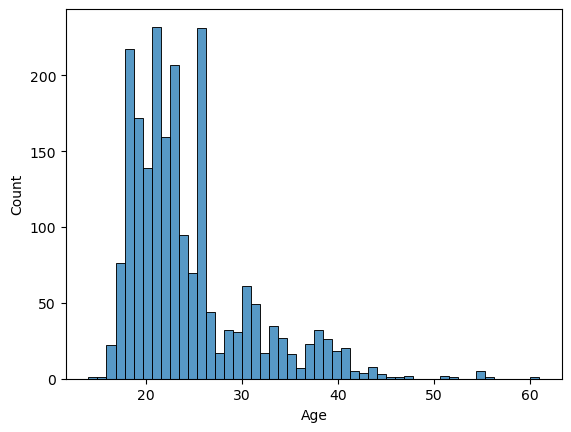

In [11]:
sns.histplot(data=df, x="Age")

<Axes: xlabel='Height', ylabel='Count'>

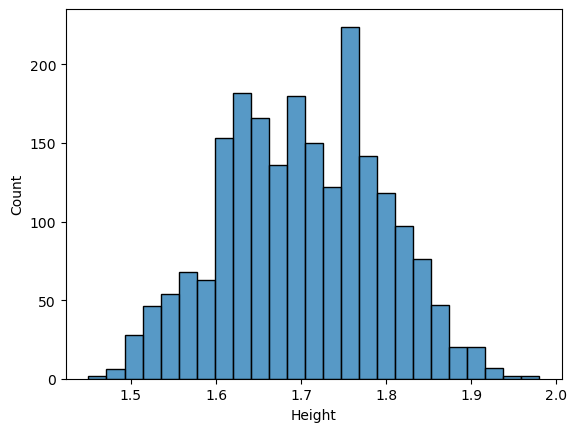

In [12]:
sns.histplot(data=df, x="Height")

<Axes: xlabel='Weight', ylabel='Count'>

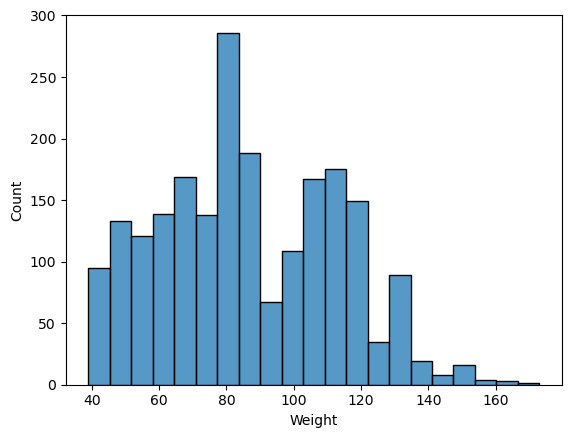

In [13]:
sns.histplot(data=df, x="Weight")

In [14]:
# Indicate the unique values in the numeric and categorical columns
num_col = ['Age', 'Height', 'Weight', 'FCVC', 'NCP', 'CH2O', 'FAF', 'TUE']

# Convert numeric columns
for col in num_col:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors='coerce')

# No resign
df[num_col].info()

print("Updated data types for numeric columns:")
print(df[num_col].dtypes)

<class 'pandas.DataFrame'>
RangeIndex: 2111 entries, 0 to 2110
Data columns (total 8 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Age     2111 non-null   float64
 1   Height  2111 non-null   float64
 2   Weight  2111 non-null   float64
 3   FCVC    2111 non-null   float64
 4   NCP     2111 non-null   float64
 5   CH2O    2111 non-null   float64
 6   FAF     2111 non-null   float64
 7   TUE     2111 non-null   float64
dtypes: float64(8)
memory usage: 132.1 KB
Updated data types for numeric columns:
Age       float64
Height    float64
Weight    float64
FCVC      float64
NCP       float64
CH2O      float64
FAF       float64
TUE       float64
dtype: object


In [15]:
# Indicate the unique values in the columns
columns = ['Gender', 'Age', 'Height', 'Weight', 'family_history_with_overweight', 'FAVC', 'FCVC', 'NCP','CAEC','SMOKE','CH2O','SCC',
           'FAF', 'TUE', 'CALC', 'MTRANS','NObeyesdad']

for i in columns:
    print(f'{i} unique values:' , df[i].unique())

Gender unique values: <StringArray>
['Female', 'Male']
Length: 2, dtype: str
Age unique values: [21.       23.       27.       ... 22.524036 24.361936 23.664709]
Height unique values: [1.62     1.52     1.8      ... 1.752206 1.73945  1.738836]
Weight unique values: [ 64.        56.        77.       ... 133.689352 133.346641 133.472641]
family_history_with_overweight unique values: <StringArray>
['yes', 'no']
Length: 2, dtype: str
FAVC unique values: <StringArray>
['no', 'yes']
Length: 2, dtype: str
FCVC unique values: [2.       3.       1.       2.450218 2.880161 2.00876  2.596579 2.591439
 2.392665 1.123939 2.027574 2.658112 2.88626  2.714447 2.750715 1.4925
 2.205439 2.059138 2.310423 2.823179 2.052932 2.596364 2.767731 2.815157
 2.737762 2.568063 2.524428 2.971574 1.0816   1.270448 1.344854 2.959658
 2.725282 2.844607 2.44004  2.432302 2.592247 2.449267 2.929889 2.015258
 1.031149 1.592183 1.21498  1.522001 2.703436 2.362918 2.14084  2.5596
 2.336044 1.813234 2.724285 2.71897  1.133

In [16]:
# Clean target just in case there are missing values
df['NObeyesdad'] = df['NObeyesdad'].astype(str).str.strip()

# LabelEncoder
le = LabelEncoder()
df["NObeyesdad"] = le.fit_transform(df["NObeyesdad"])

# Target with 7 levels
target_map = {'Insufficient_Weight': 0, 'Normal_Weight': 1, 'Overweight_Level_I': 2, 'Overweight_Level_II': 3, 'Obesity_Type_I': 4,
              'Obesity_Type_II': 5, 'Obesity_Type_III': 6}

df['NObeyesdad'] = df['NObeyesdad'].replace(target_map)

# Binary map
binary_map = {'no': 0, 'yes': 1}
df['family_history_with_overweight'] = df['family_history_with_overweight'].replace(binary_map)
df['FAVC'] = df['FAVC'].replace(binary_map)
df['SMOKE'] = df['SMOKE'].replace(binary_map)
df['SCC'] = df['SCC'].replace(binary_map)
df['Gender'] = df['Gender'].replace({'Female': 0, 'Male': 1})

#Categorical map
ordinal_map = {'no': 0, 'Sometimes': 1, 'Frequently': 2, 'Always': 3 }
df['CAEC'] = df['CAEC'].replace(ordinal_map)
df['CALC'] = df['CALC'].replace(ordinal_map)

# One-hot encoding nominal
mtrans_map = {'Public_transport': 0, 'Walking': 1, 'Automobile': 2, 'Motorbike': 3, 'Bike': 4}
df['MTRANS'] = df['MTRANS'].map(mtrans_map)

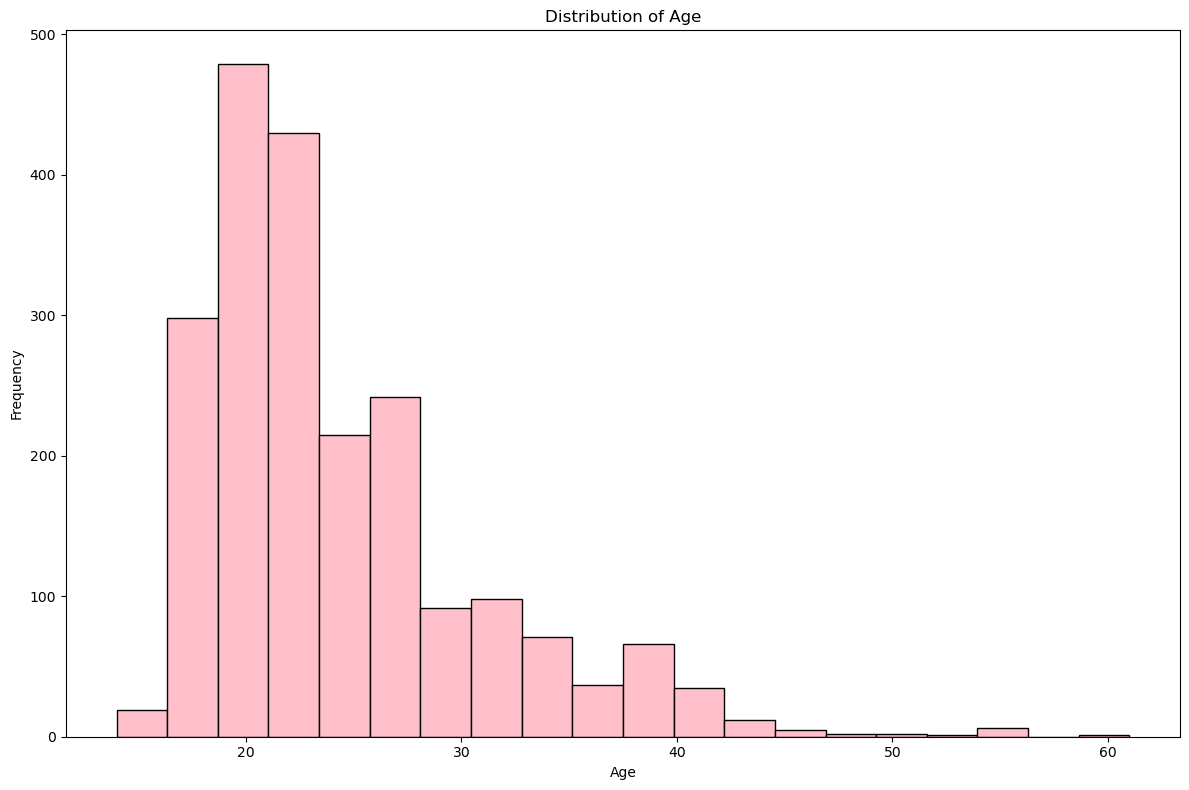

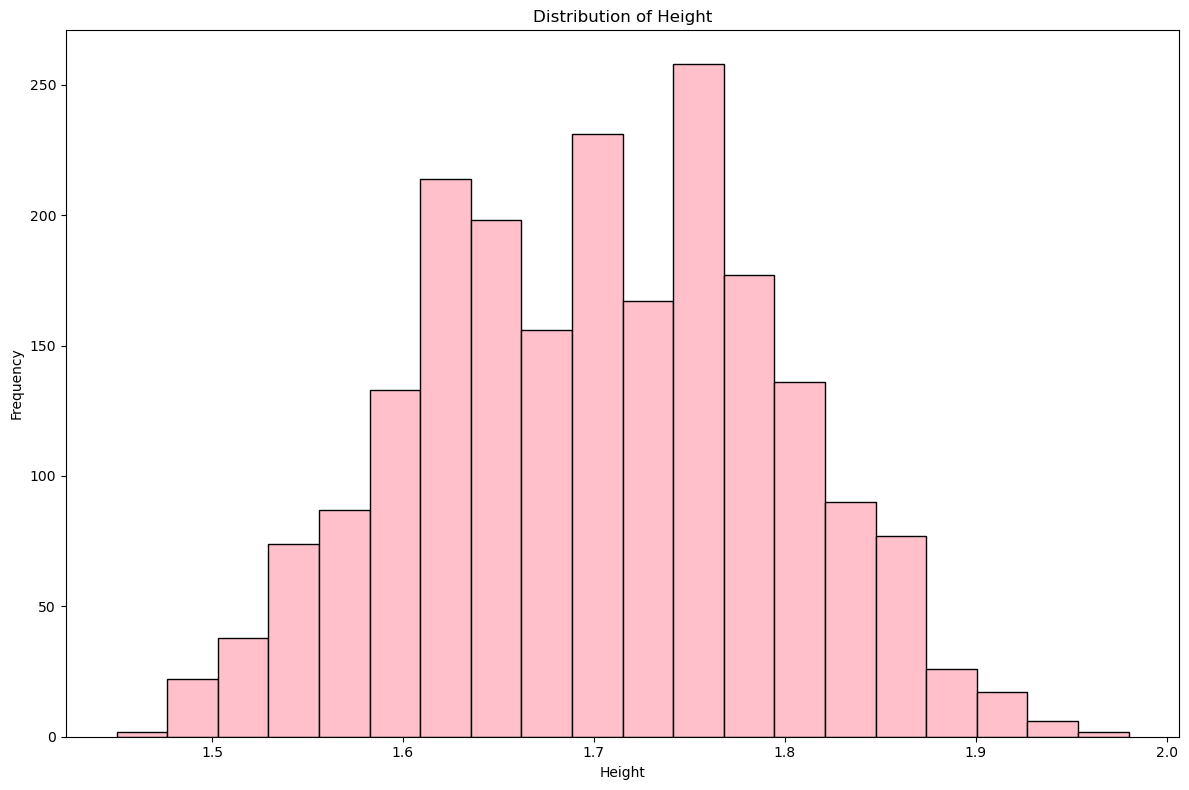

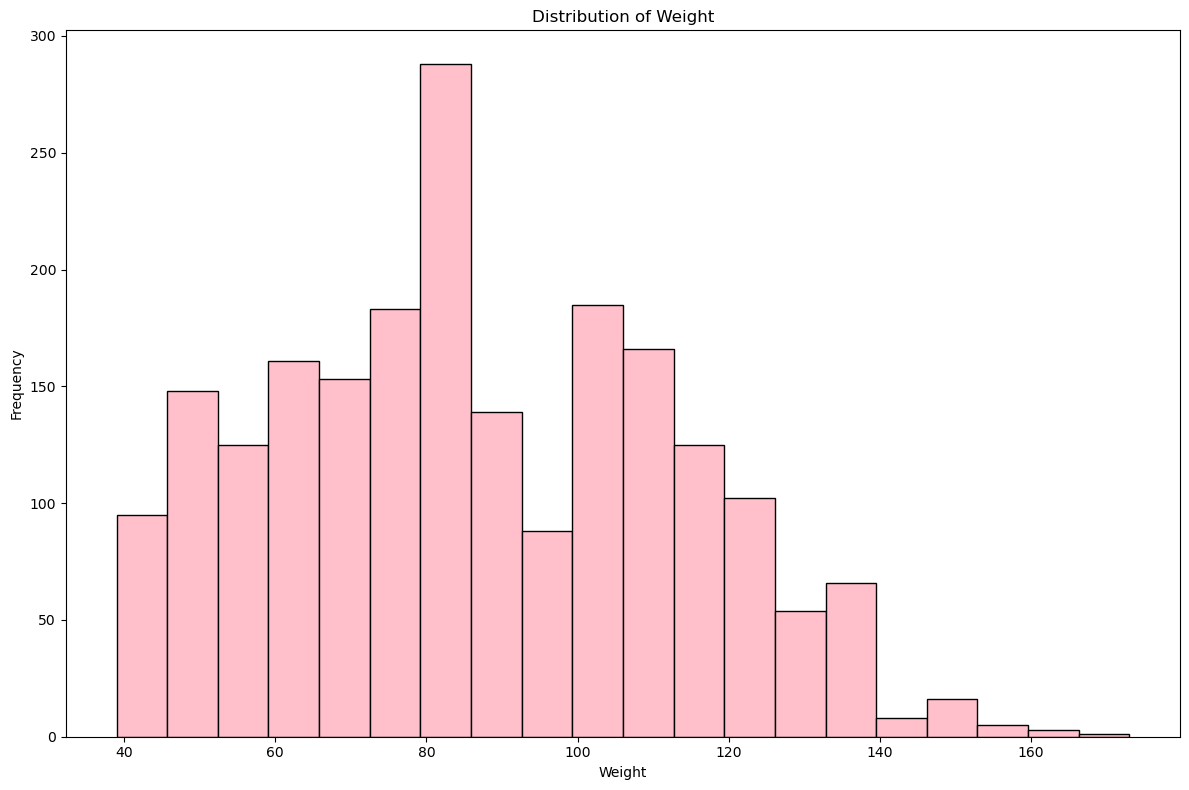

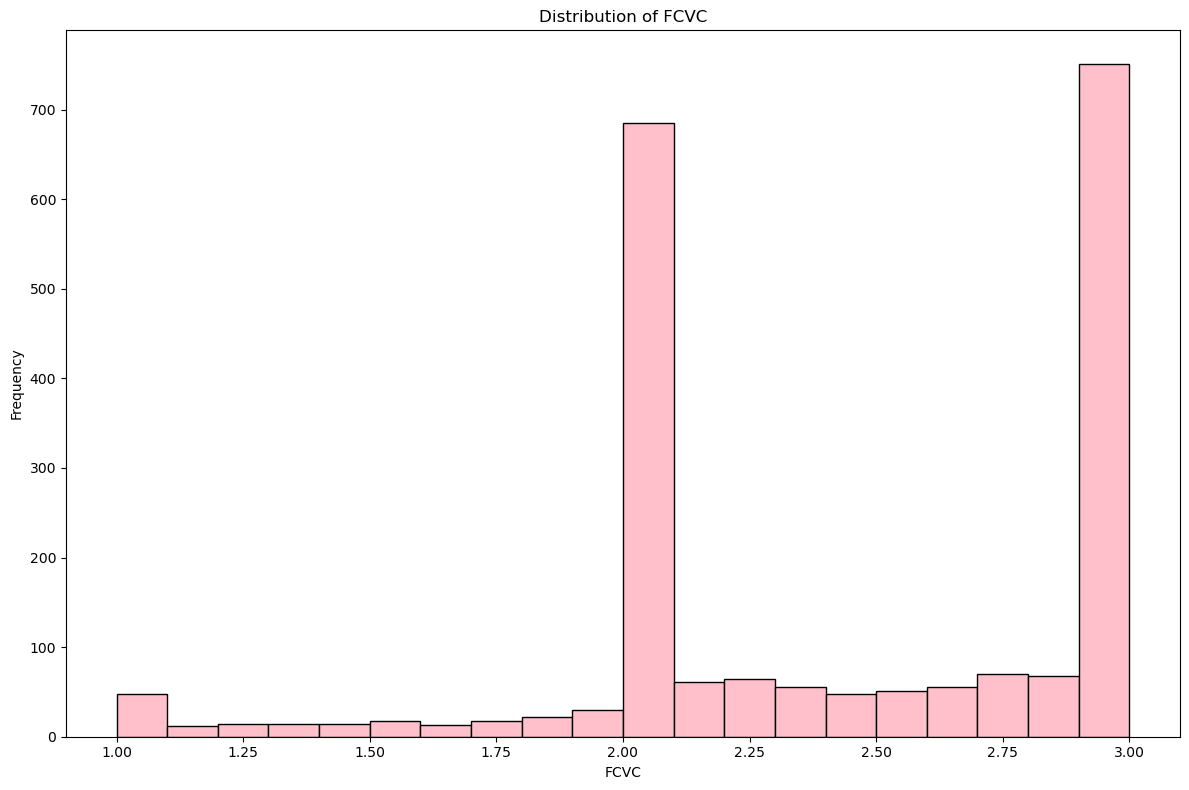

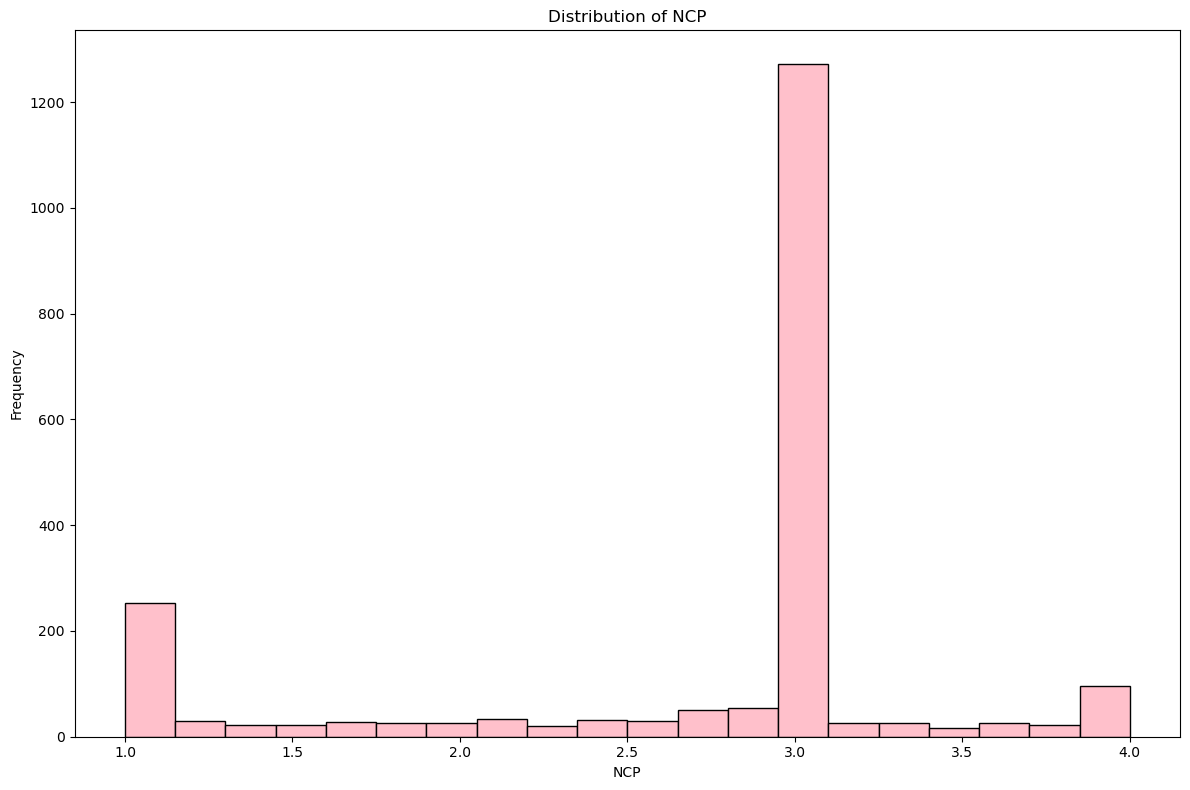

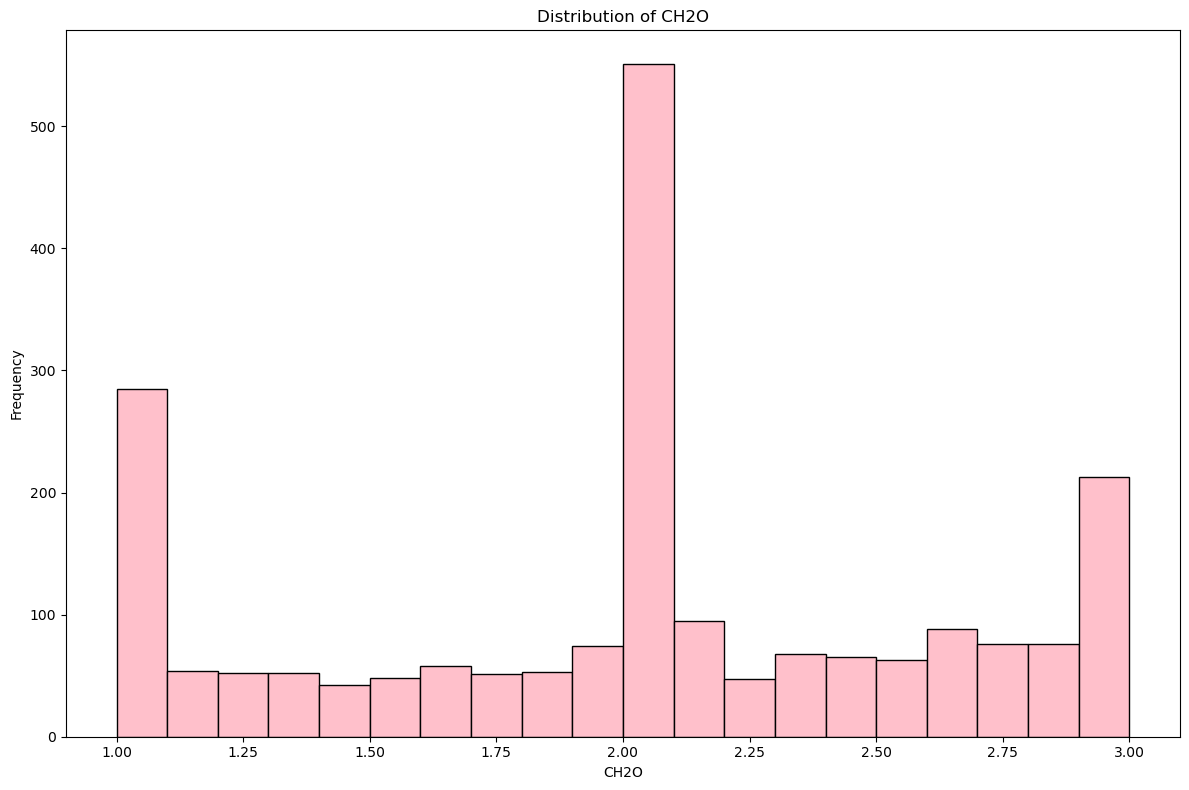

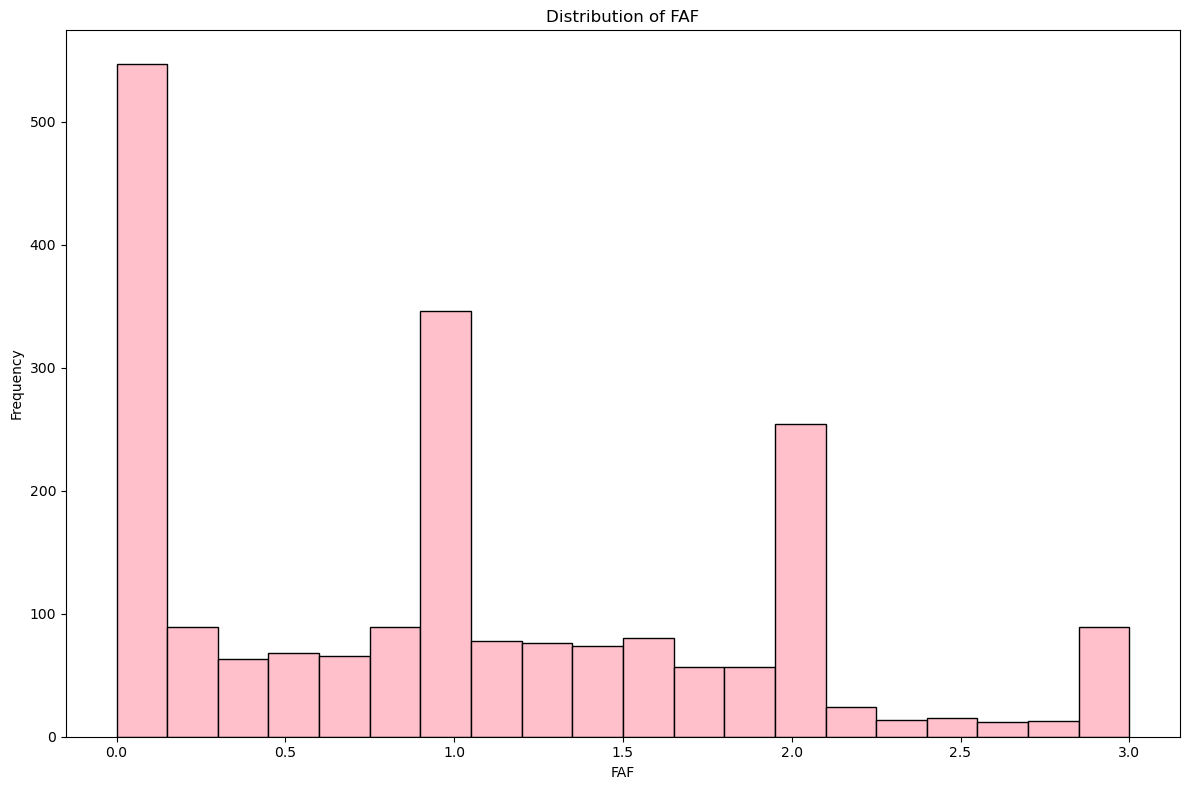

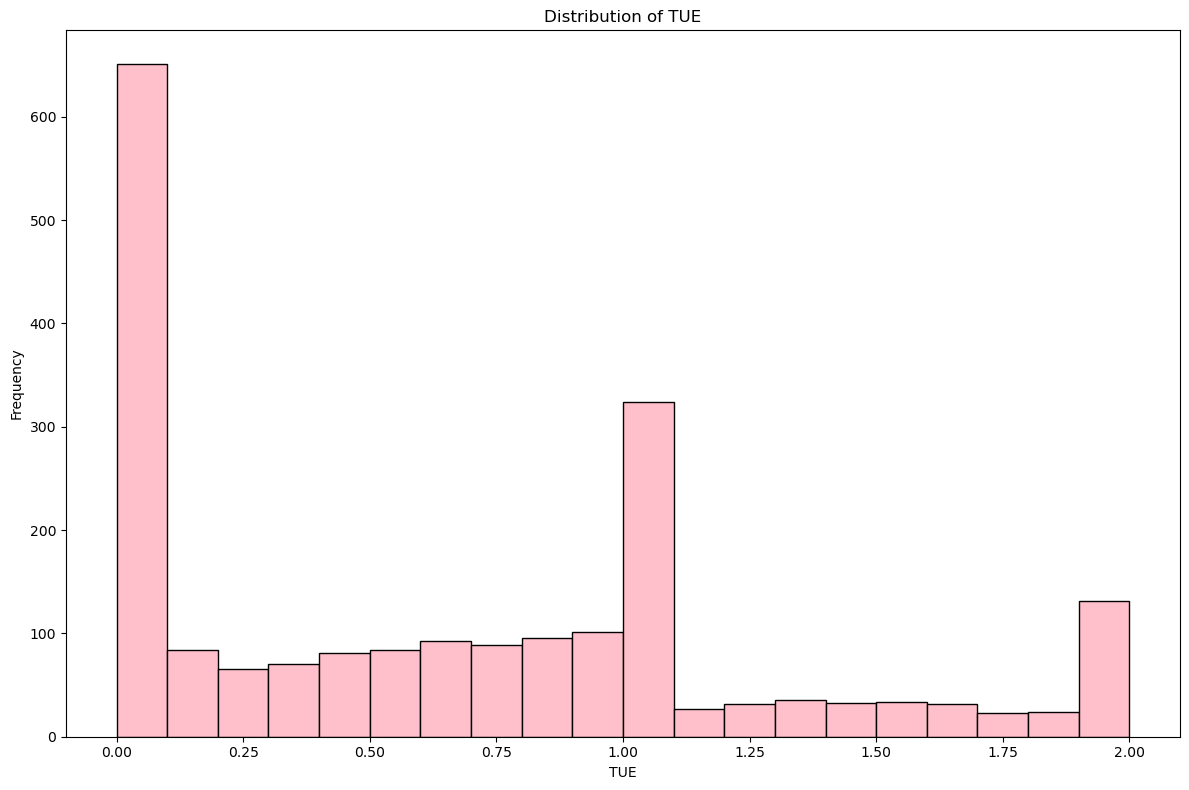

In [17]:
#Continuous columns
cont_col = ['Age', 'Height', 'Weight', 'FCVC', 'NCP', 'CH2O', 'FAF', 'TUE']

df[cont_col] = df[cont_col].apply(pd.to_numeric, errors="coerce")

for i in cont_col:
    fig, ax = plt.subplots(figsize=(12, 8))
    
# Histogram graphic
    ax.hist(df[i].dropna(), bins=20, color='pink', edgecolor='black')
    ax.set_title(f'Distribution of {i}')
    ax.set_xlabel(i)
    ax.set_ylabel('Frequency')
    plt.tight_layout()
    plt.show()

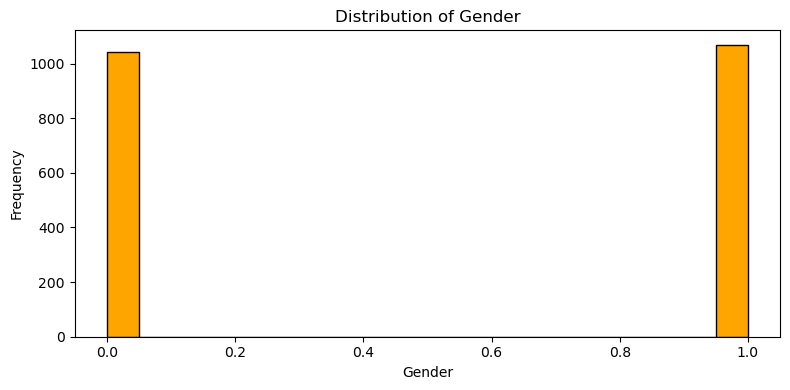

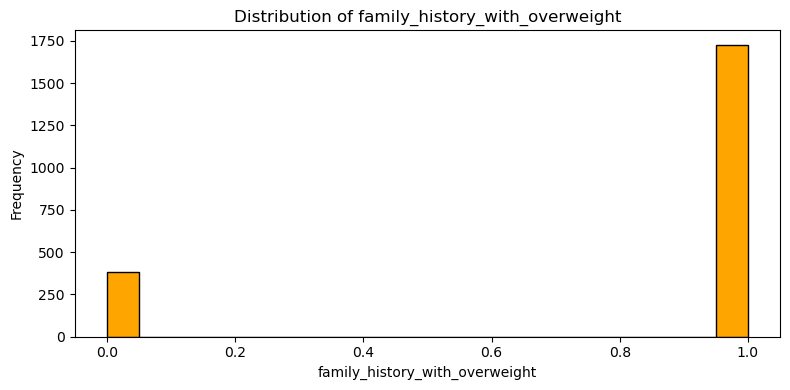

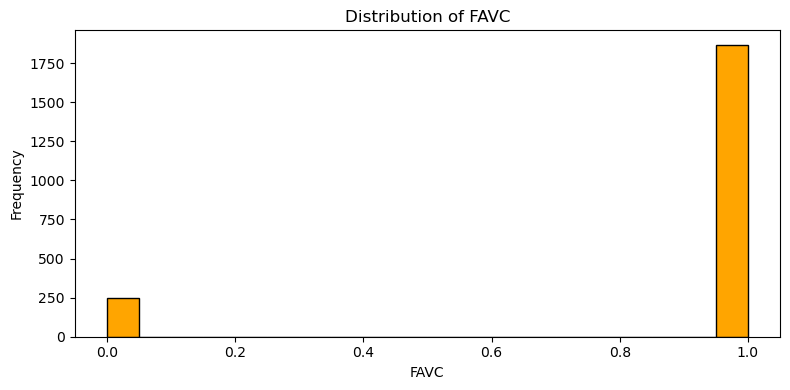

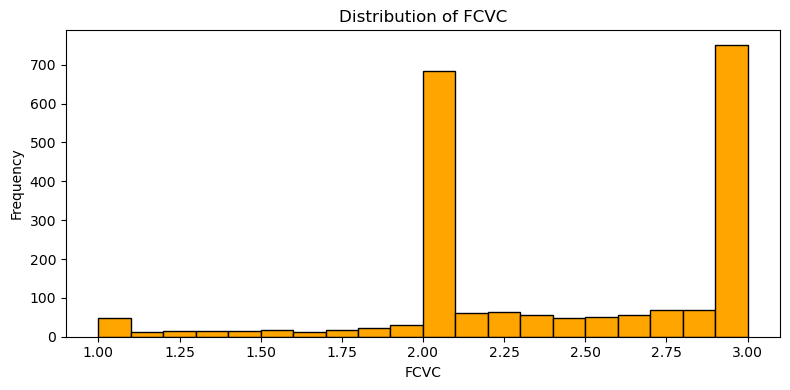

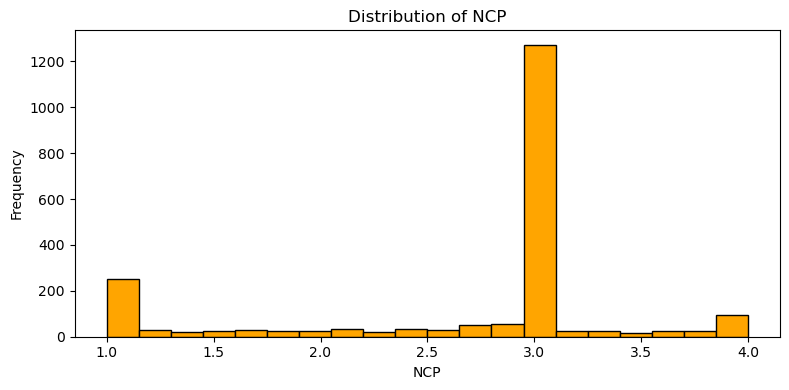

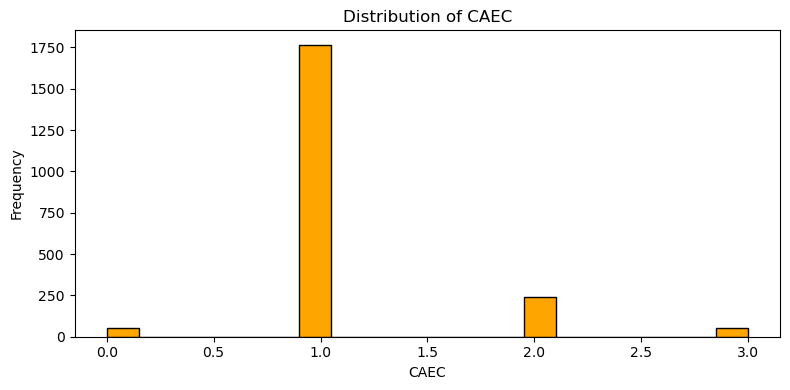

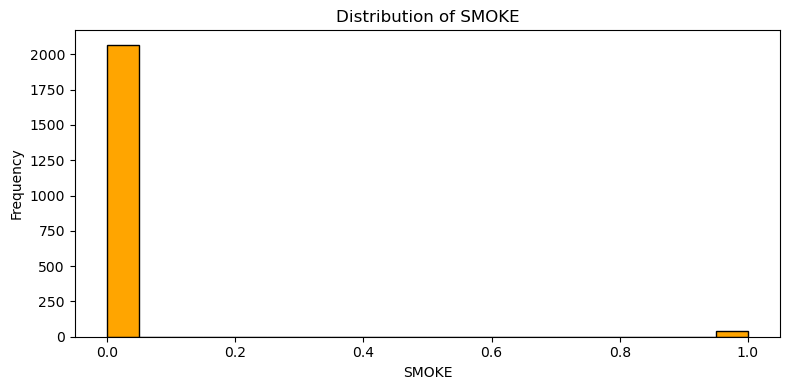

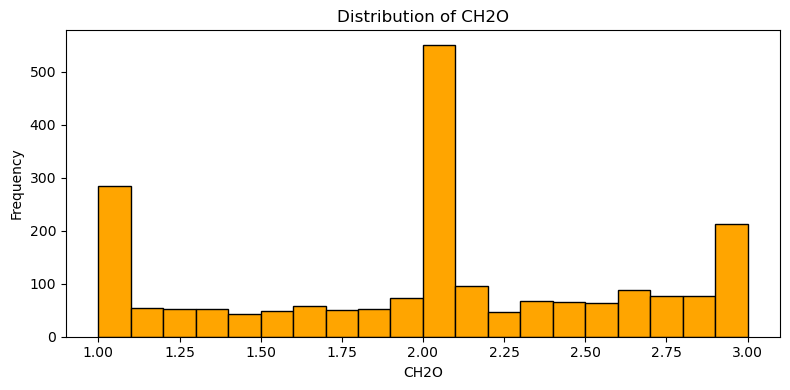

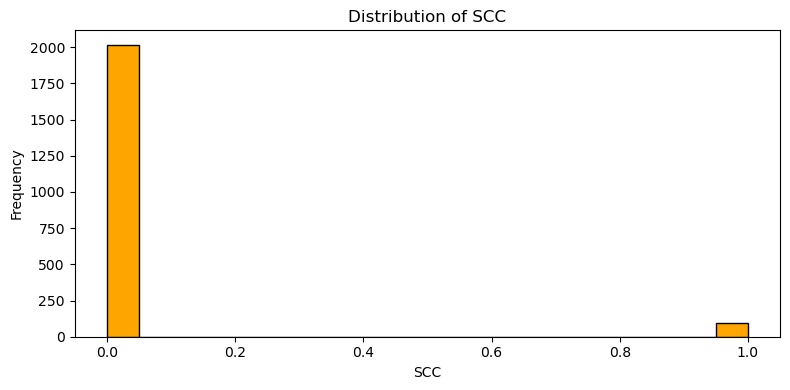

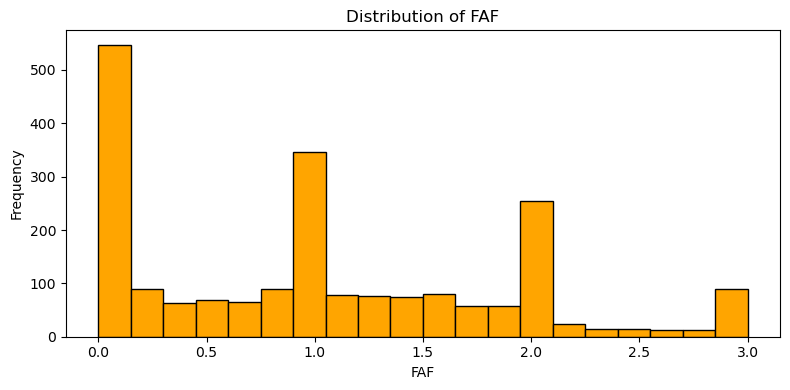

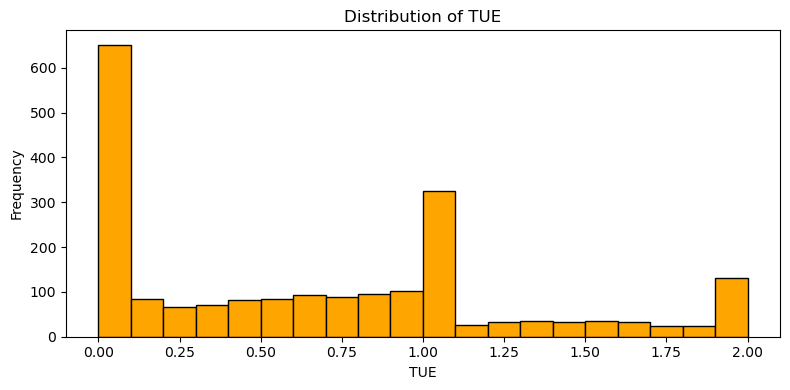

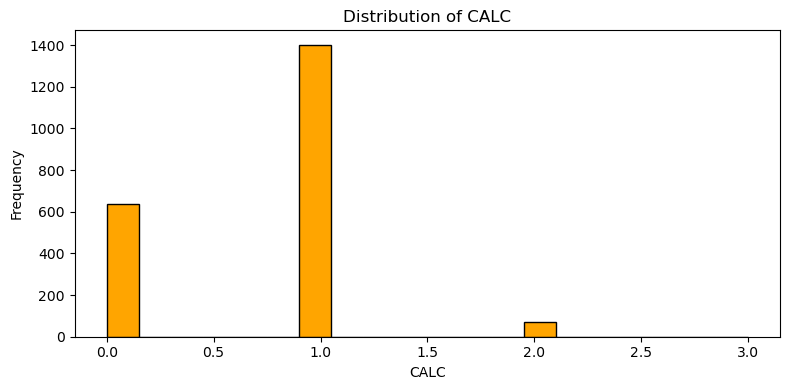

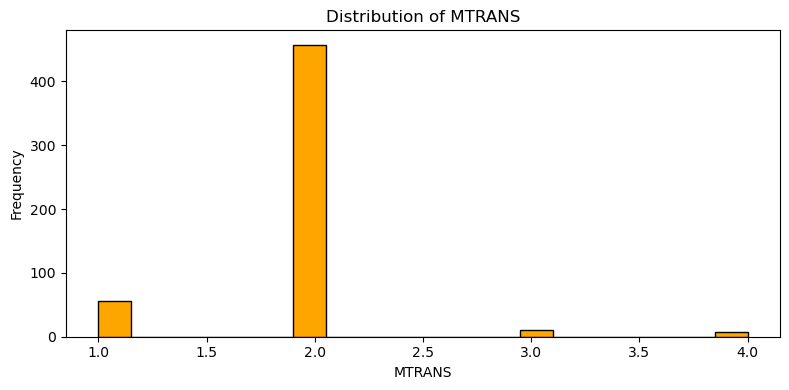

In [18]:
#Integer columns
integ_col = ['Gender', 'family_history_with_overweight', 'FAVC', 'FCVC', 'NCP', 'CAEC', 'SMOKE', 'CH2O', 'SCC', 'FAF', 'TUE', 'CALC', 'MTRANS']
    
# Histogram
for i in integ_col:
    if i in df.columns:
        fig,ax = plt.subplots(figsize=(8,4))
        ax.hist(df[i].dropna(), bins=20, color='orange', edgecolor='black')
        ax.set_title(f'Distribution of {i}')
        ax.set_xlabel(i)
        ax.set_ylabel('Frequency')
        plt.tight_layout()
        plt.show()

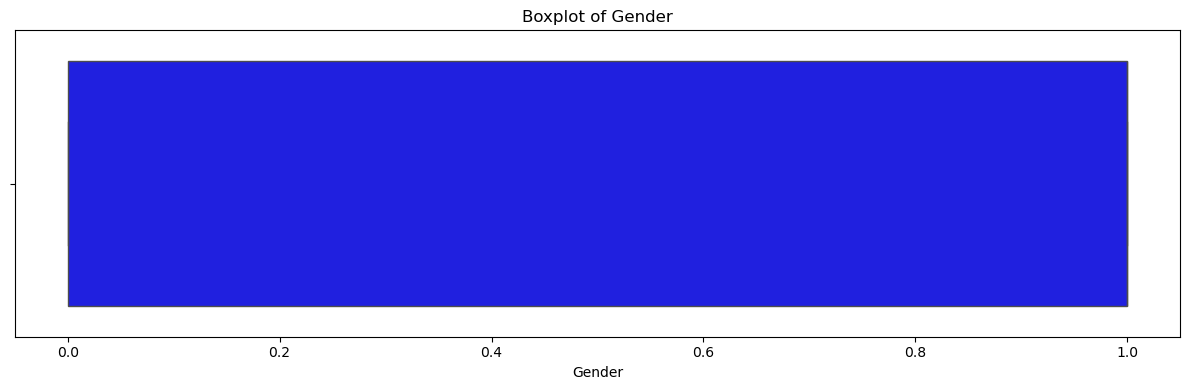

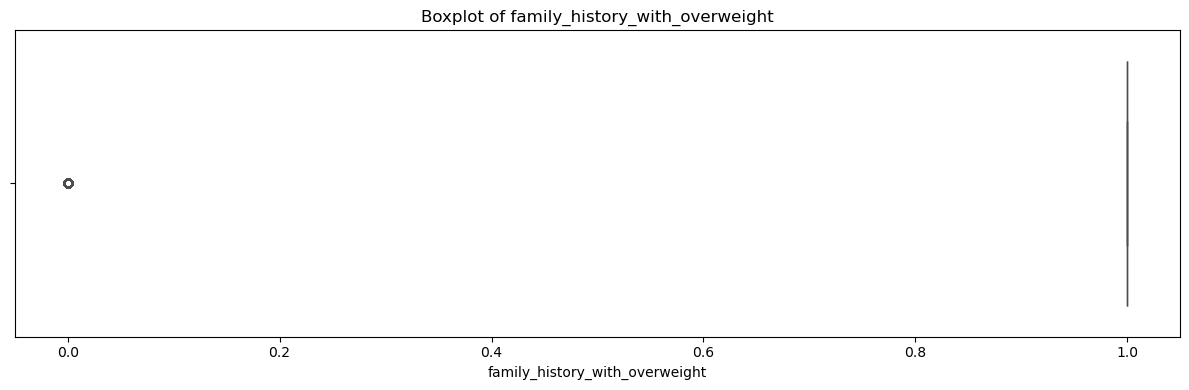

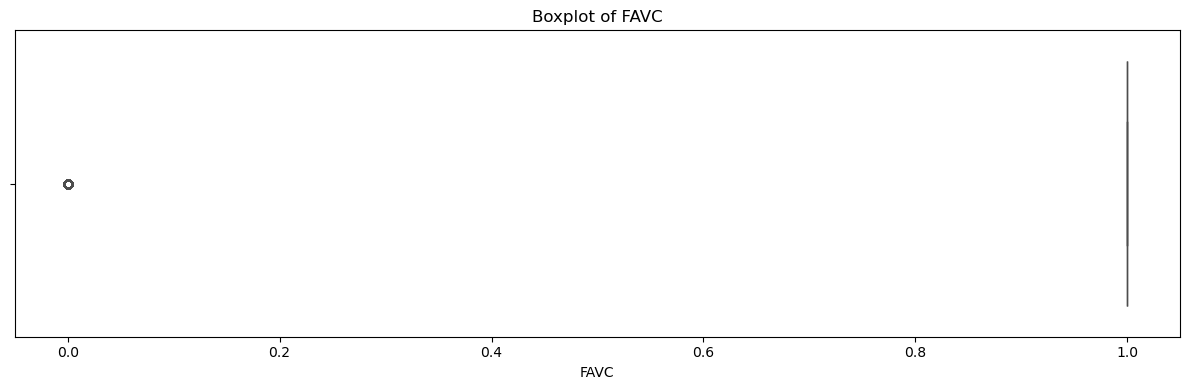

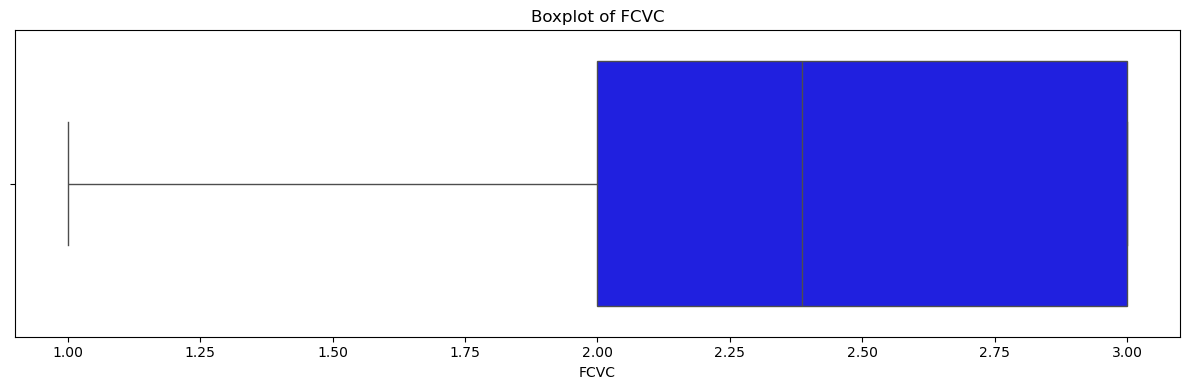

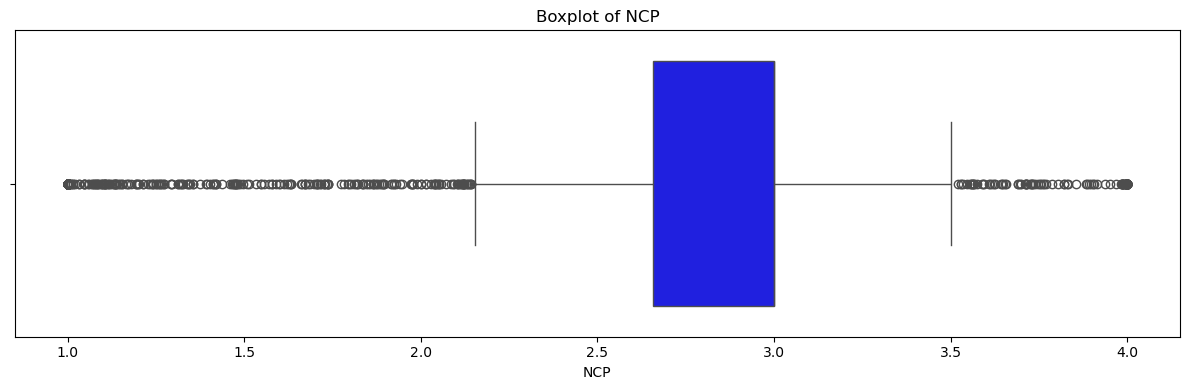

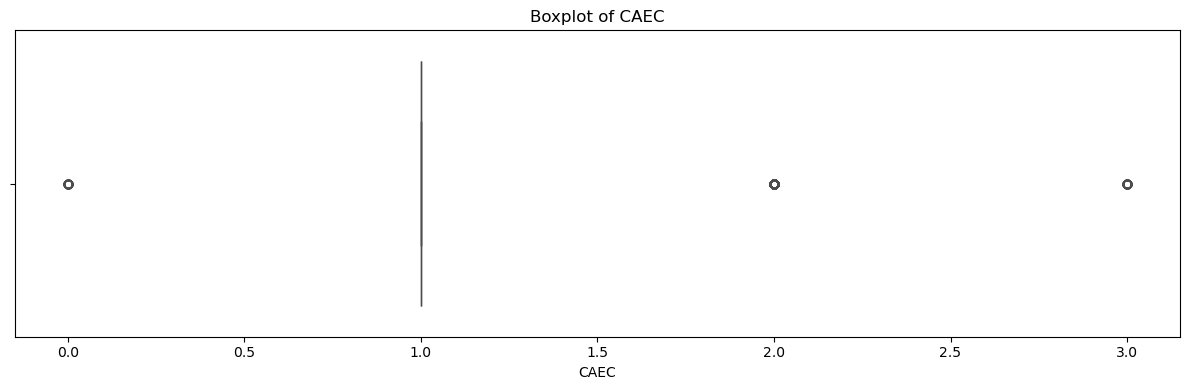

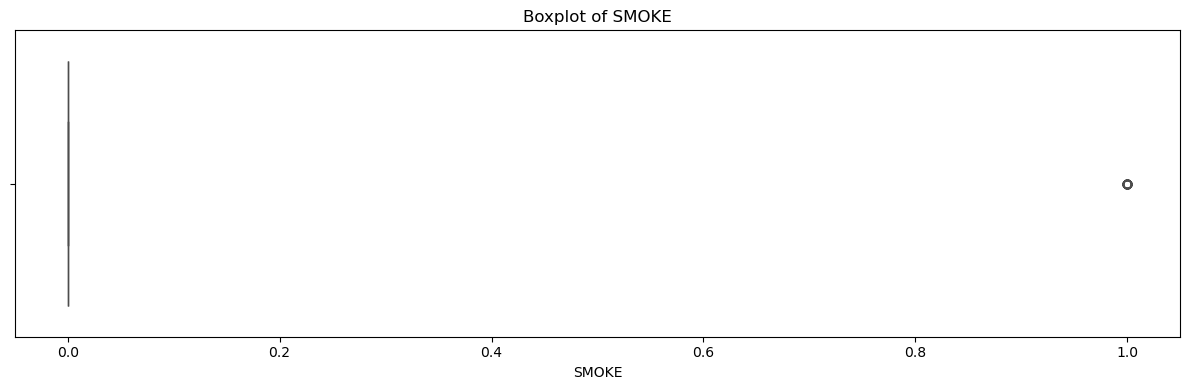

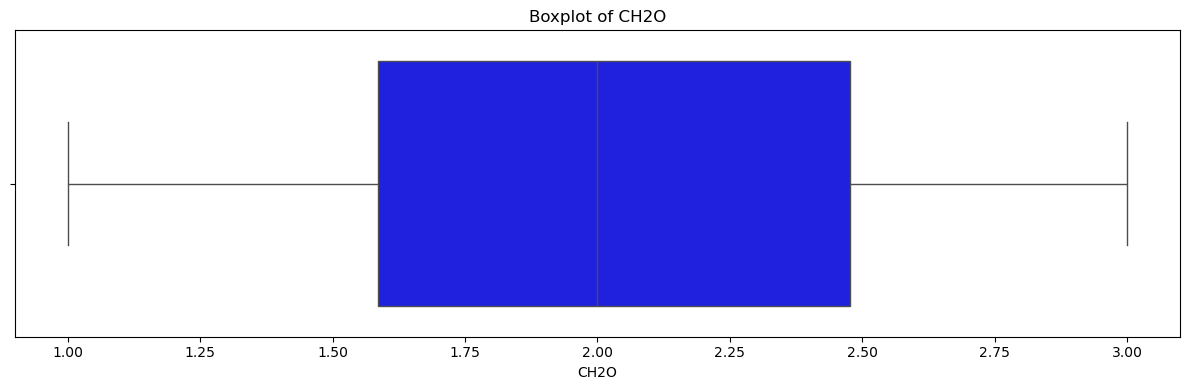

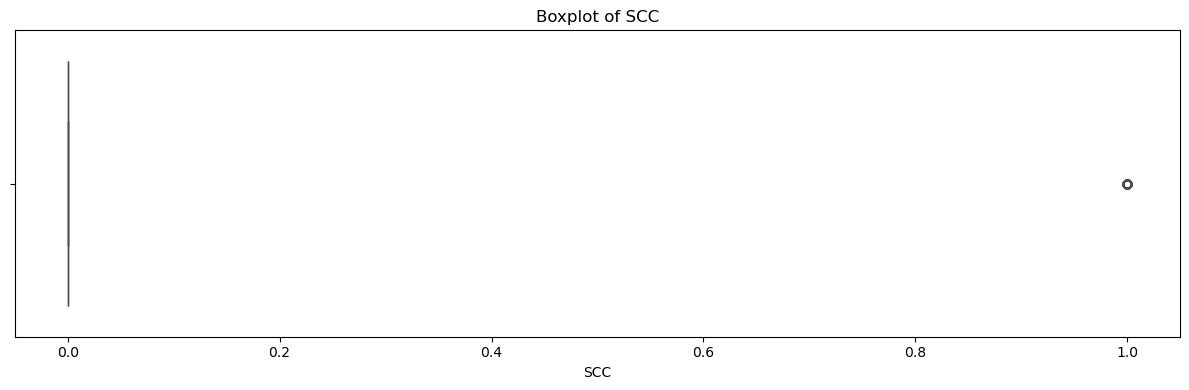

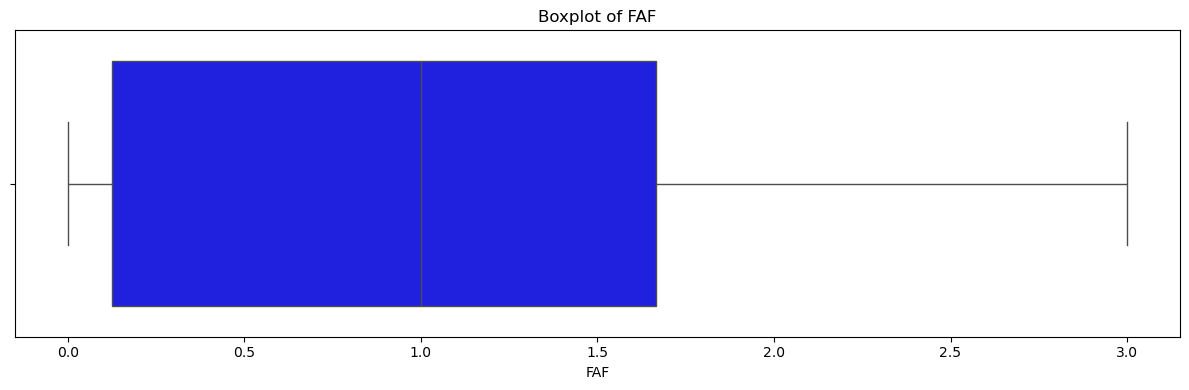

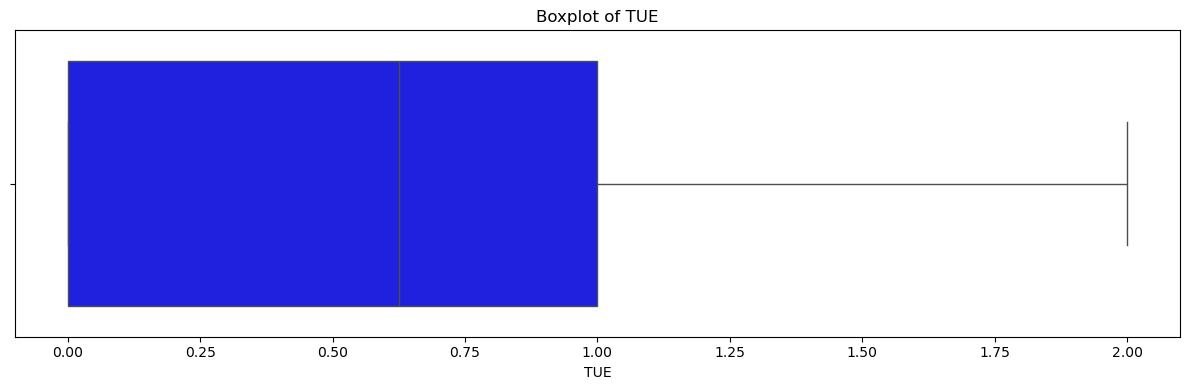

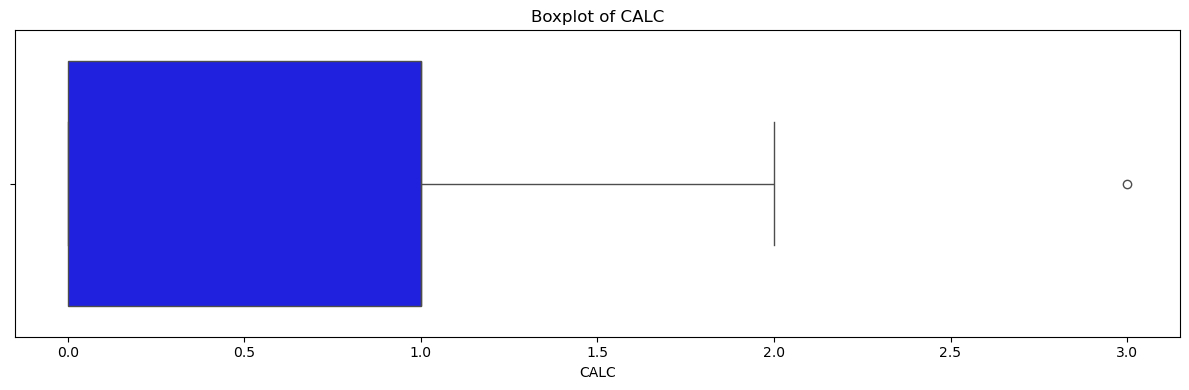

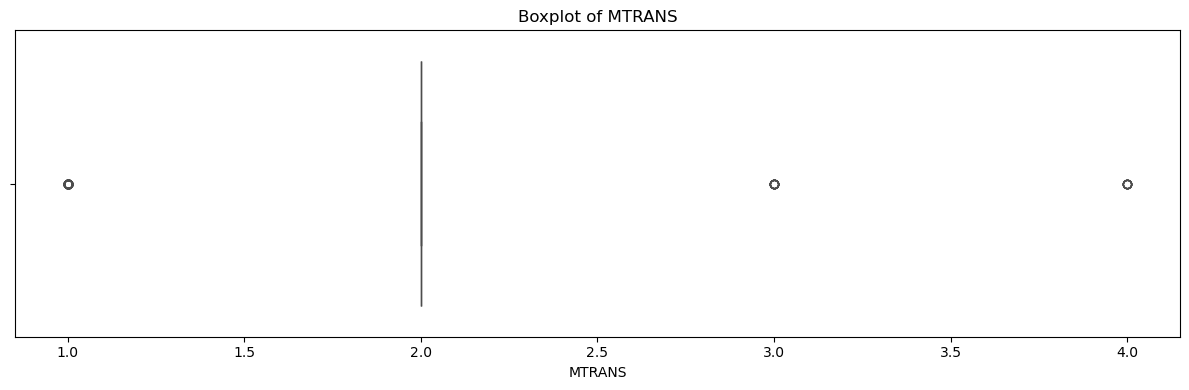

In [19]:
#Boxplot
for i in integ_col:
    if i in df.columns:
        plt.figure(figsize=(12, 4))
    
        # Histogram
        sns.boxplot(x=df[i].dropna(), color='blue')
    
        plt.title(f'Boxplot of {i}') 
        plt.xlabel(i)
        plt.tight_layout()
        plt.show()

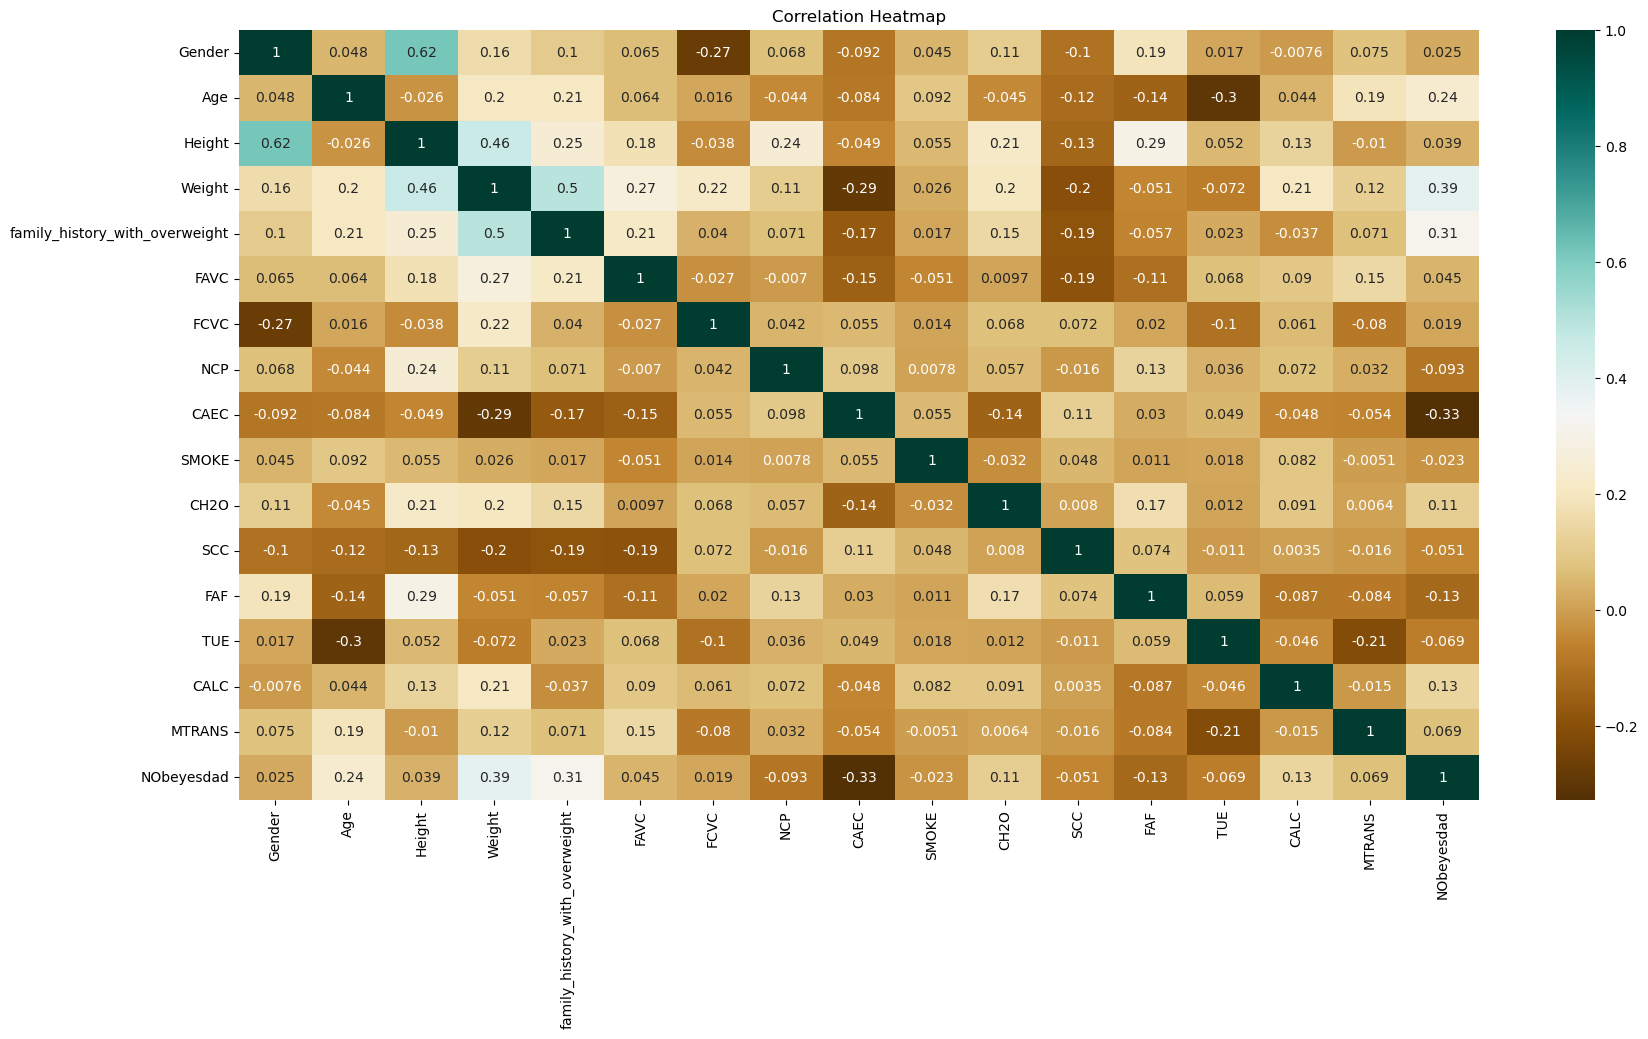

In [20]:
#Heatmap
df['NObeyesdad'] = df['NObeyesdad'].apply(pd.to_numeric, errors="coerce")

df_numeric = df.apply(pd.to_numeric, errors='coerce')

plt.figure(figsize=(20,10))
plt.title ("Correlation Heatmap")
c = df_numeric.corr()
sns.heatmap(c,cmap="BrBG",annot=True)
plt.show()

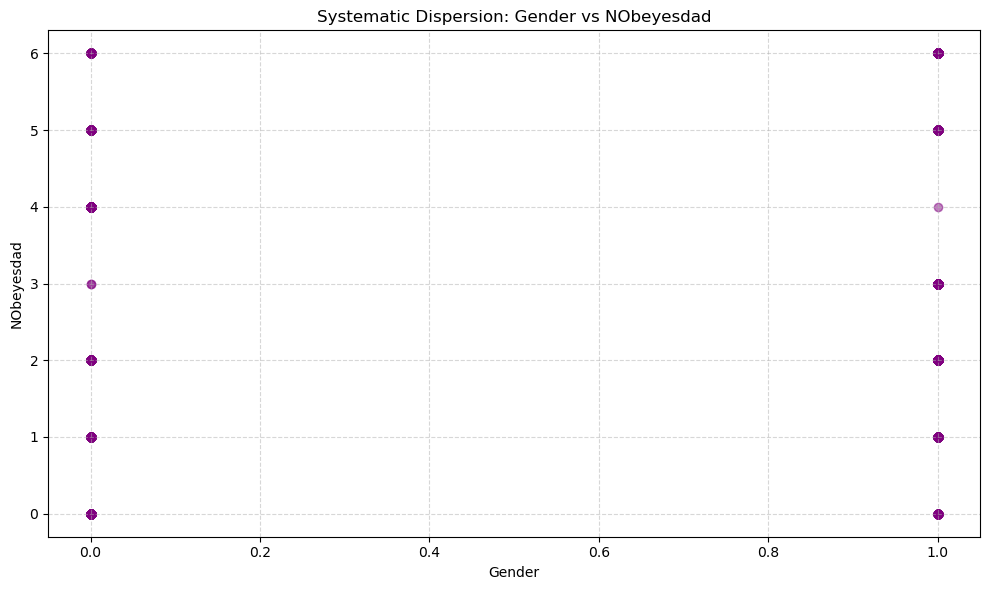

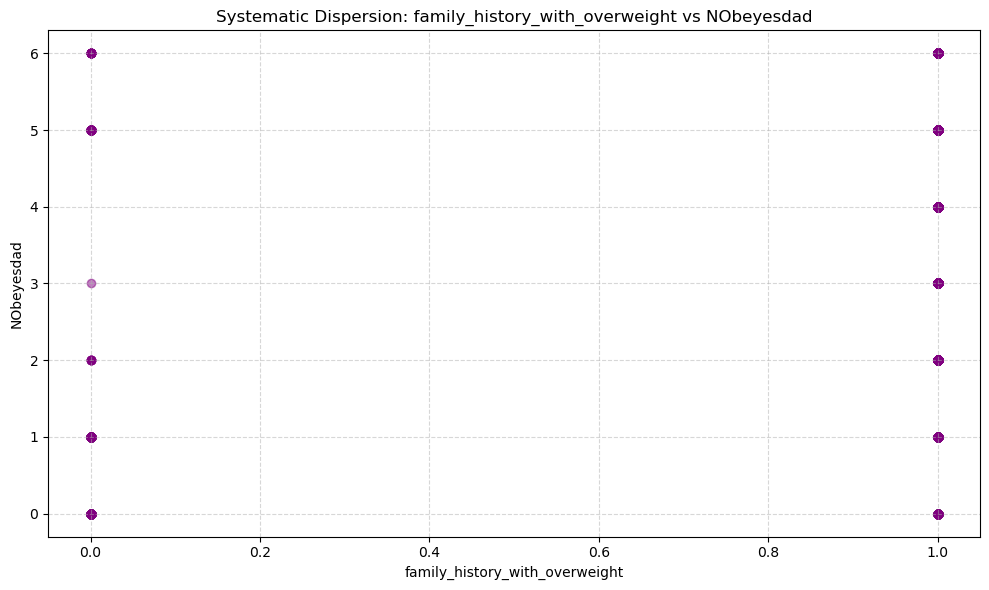

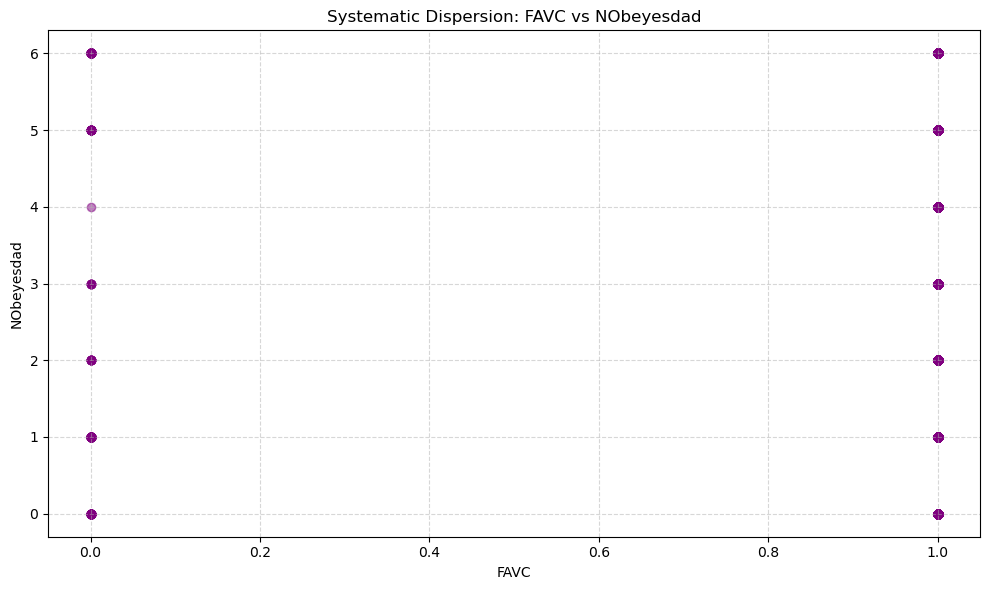

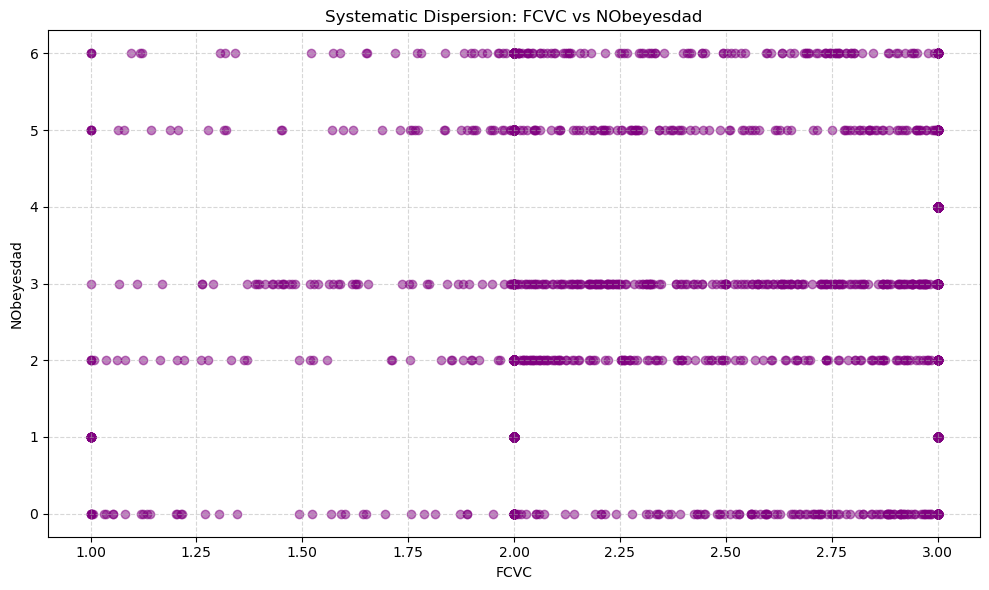

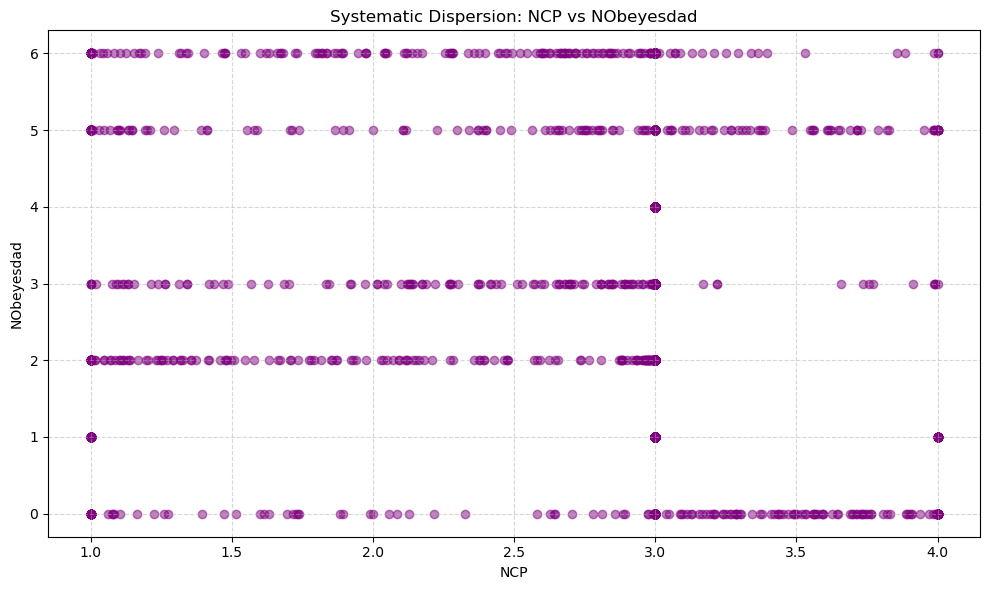

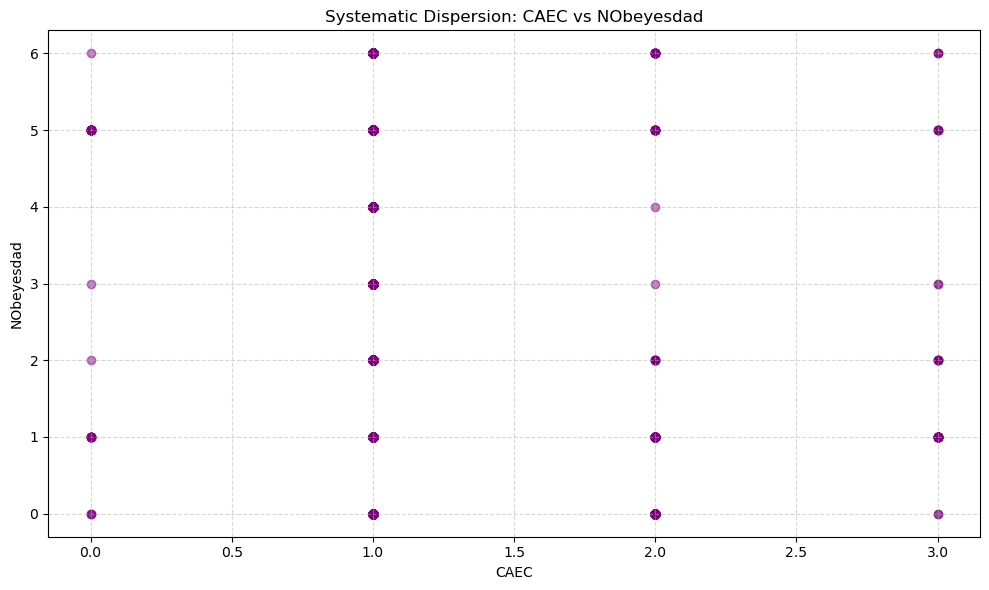

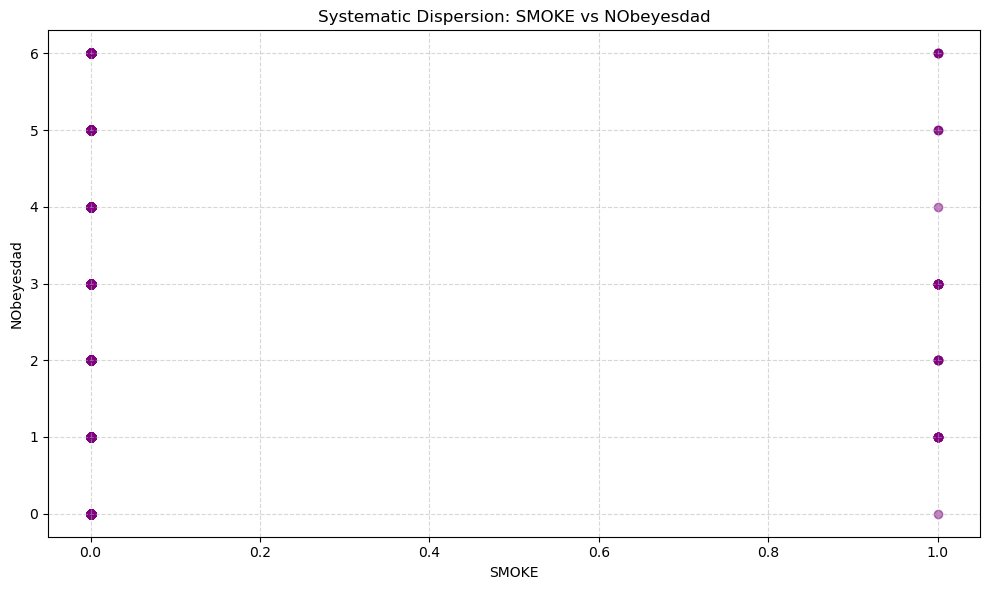

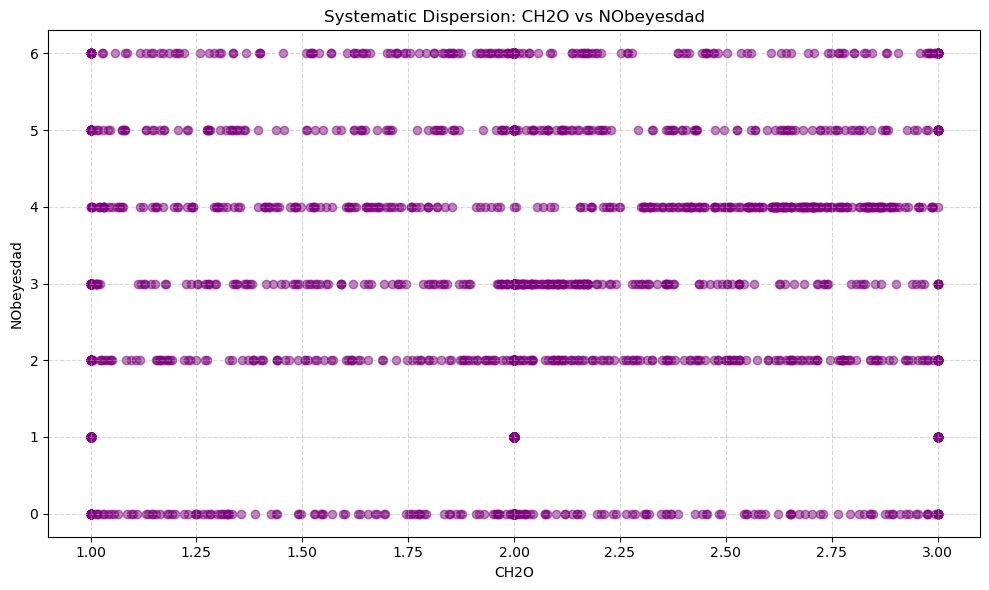

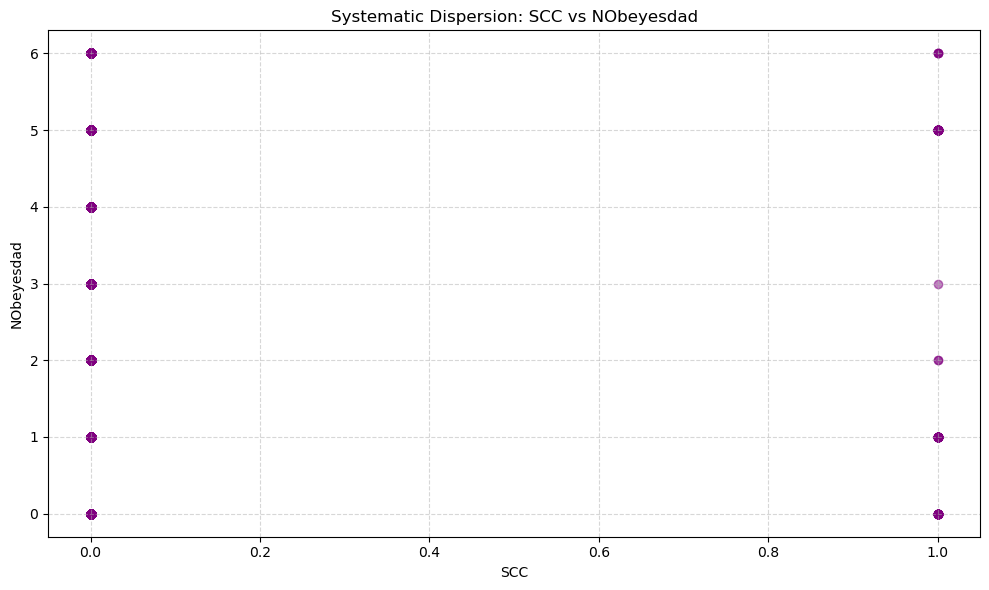

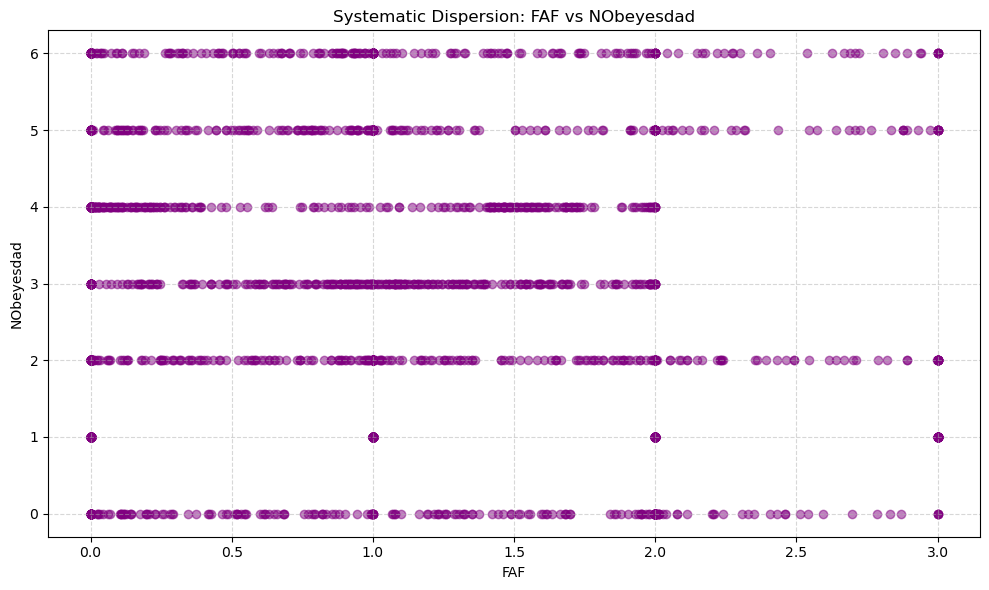

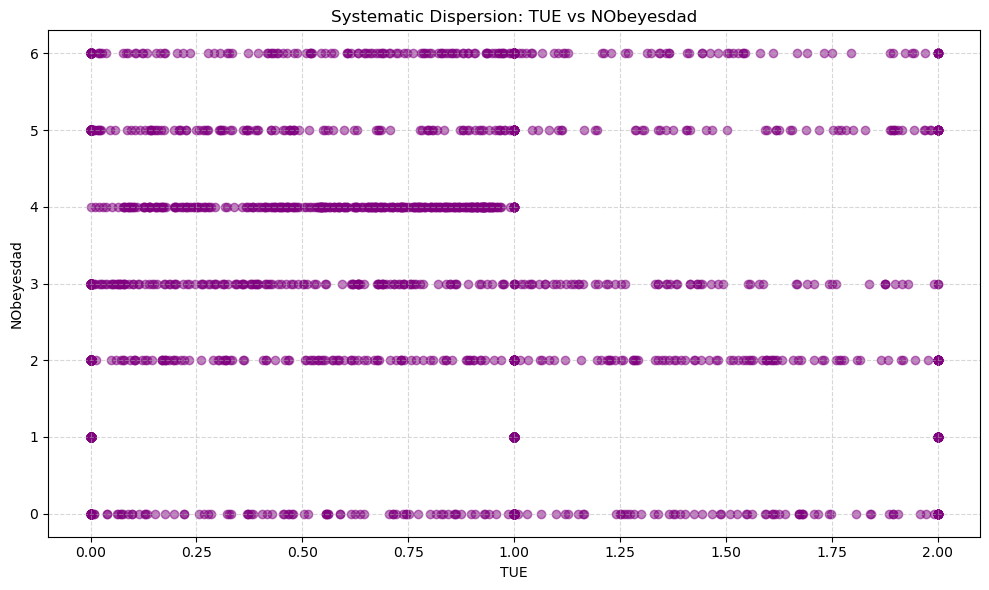

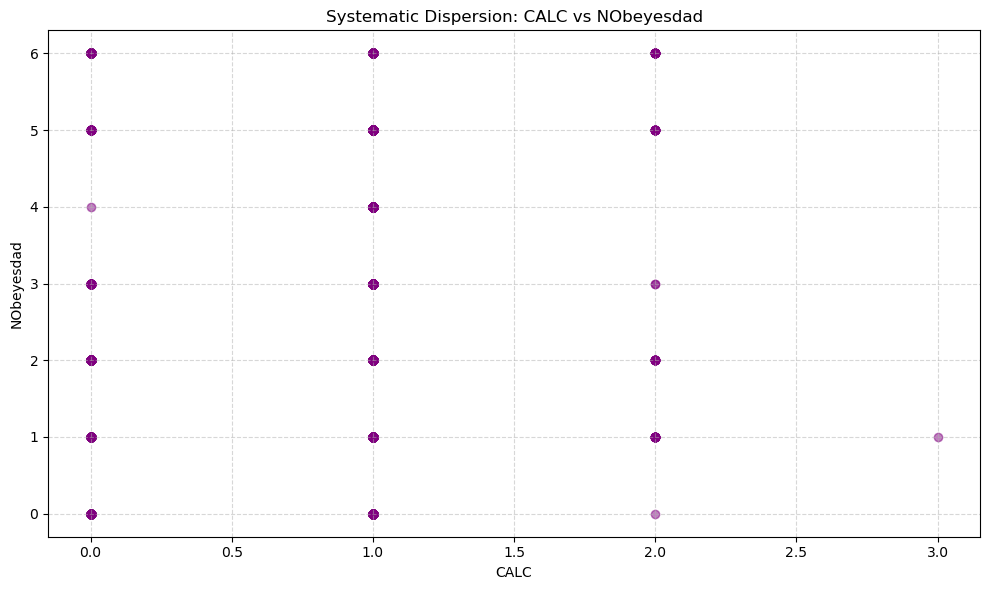

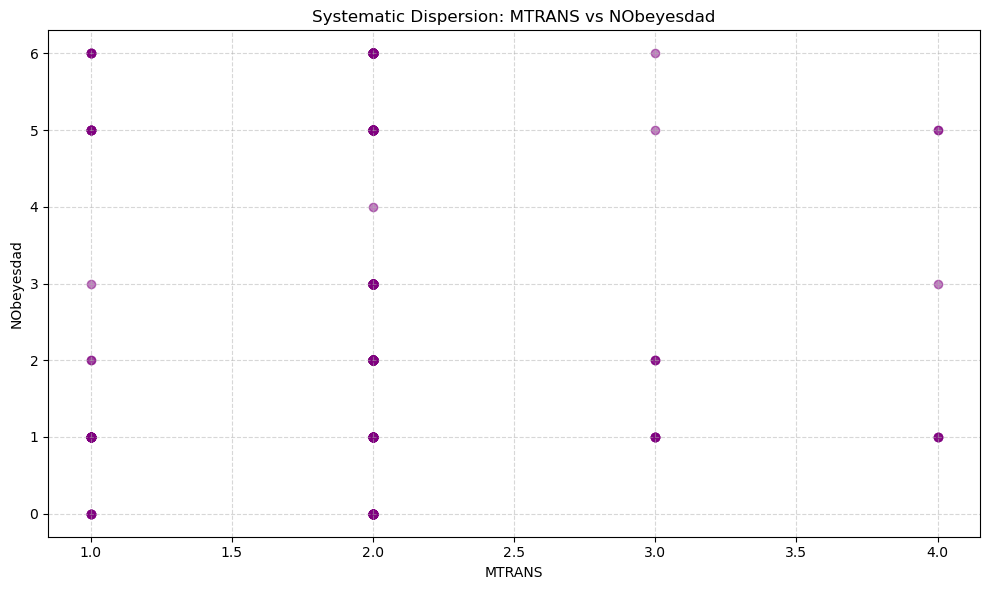

In [21]:
# Discrete and continuous columns
Target_variable = "NObeyesdad"
num_cols = [c for c in integ_col if c != Target_variable and c in df.columns]

# Numeric variable
for col in num_cols:
    fig, ax = plt.subplots(figsize=(10, 6))

    # Use alpha to different points
    ax.scatter(df[col], df[Target_variable], alpha=0.5, color="purple")
    ax.set_title(f"Systematic Dispersion: {col} vs {Target_variable}")
    ax.set_xlabel(col)
    ax.set_ylabel(Target_variable)
    ax.grid(True, linestyle="--", alpha=0.5)
    plt.tight_layout()
    plt.show()

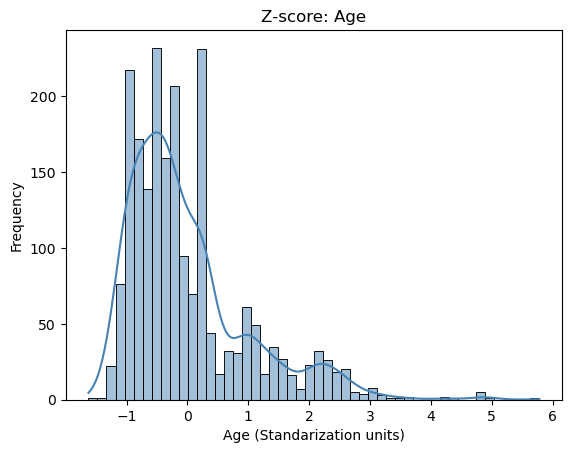

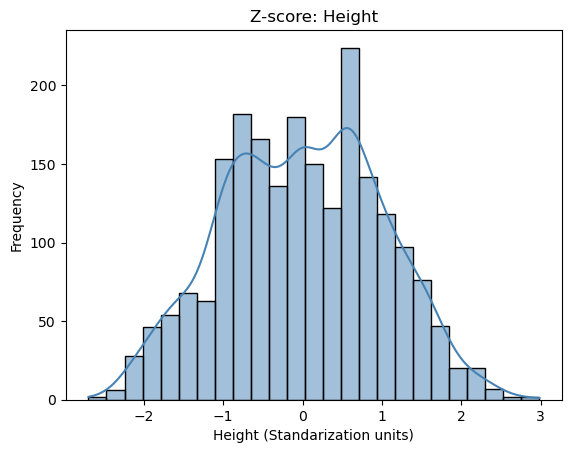

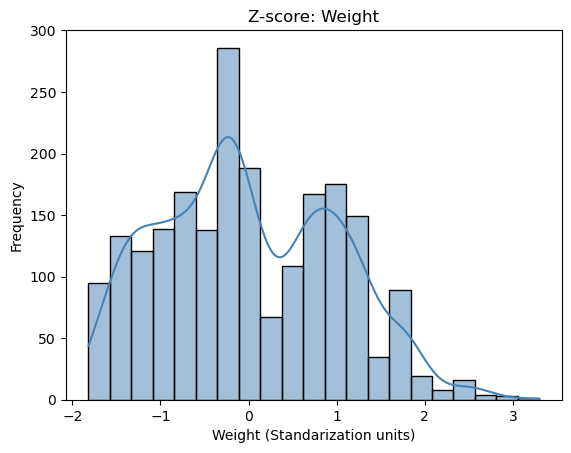

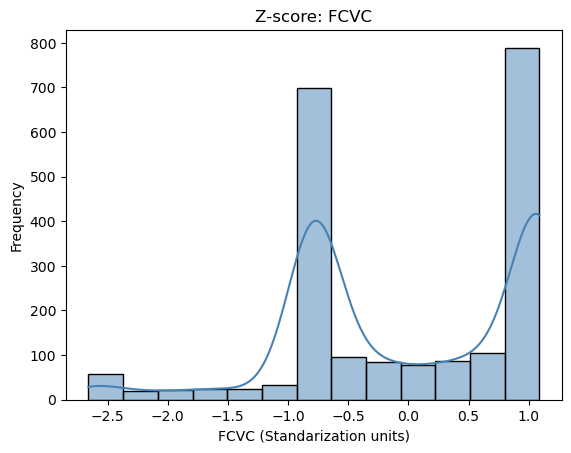

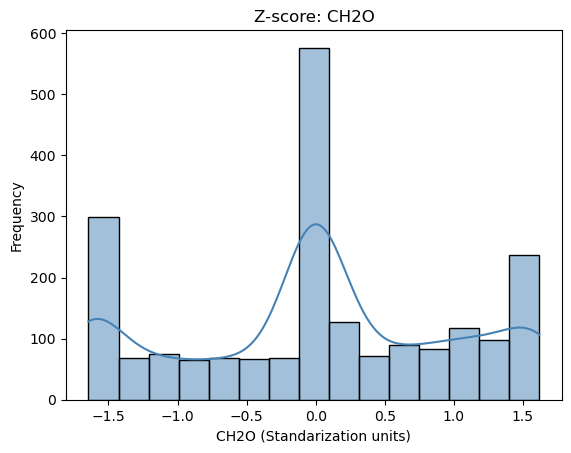

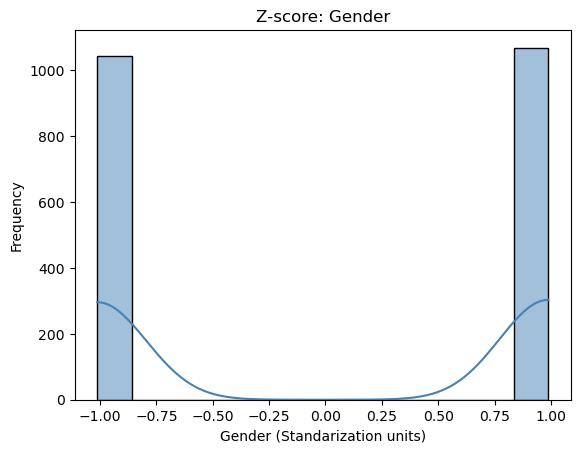

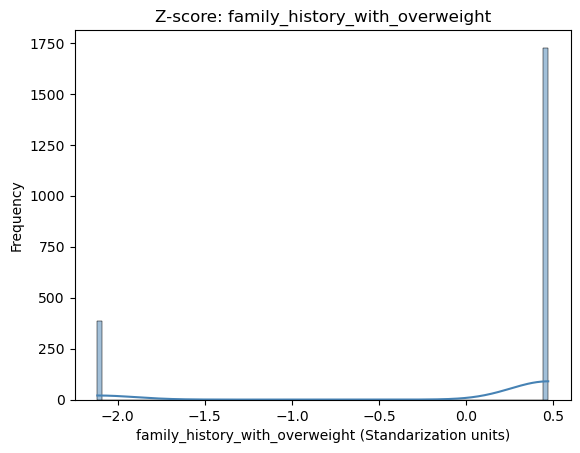

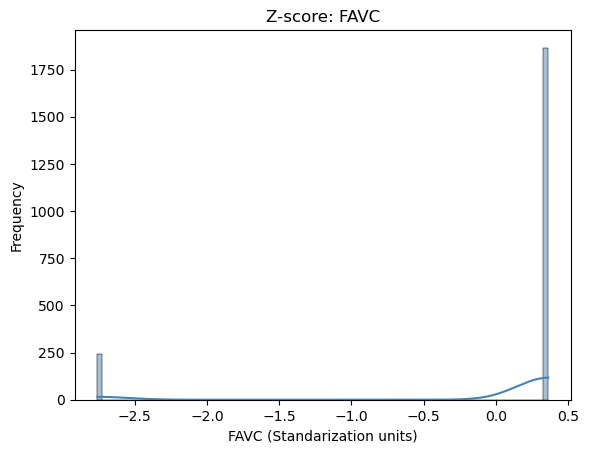

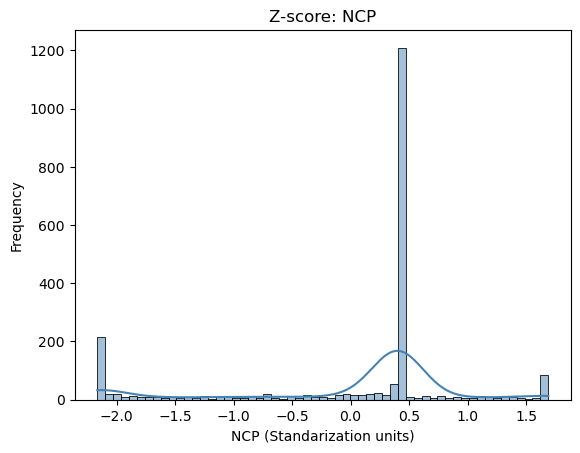

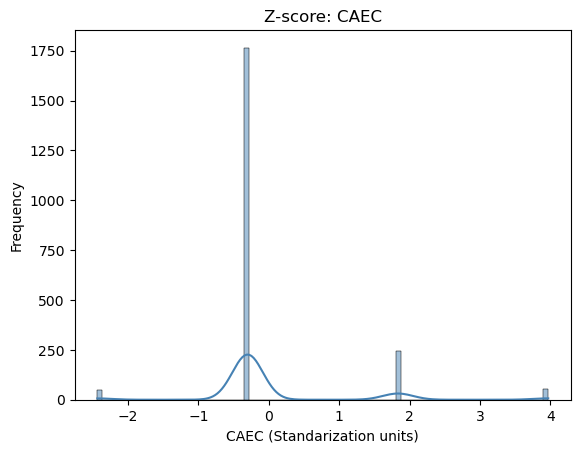

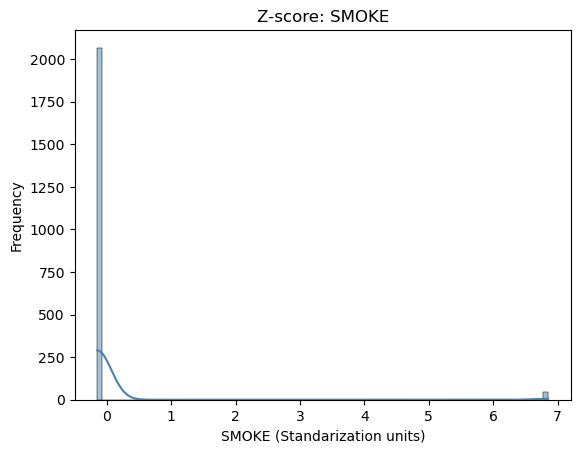

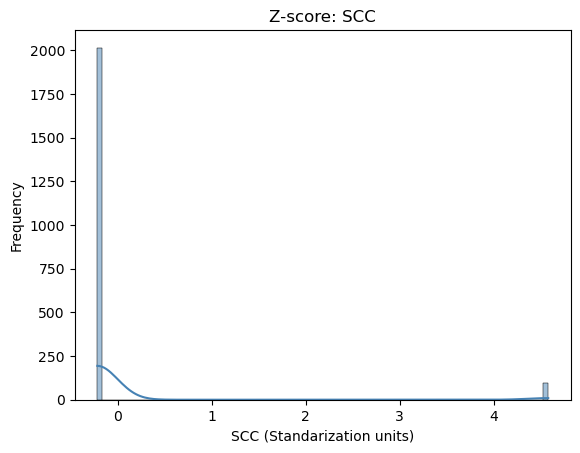

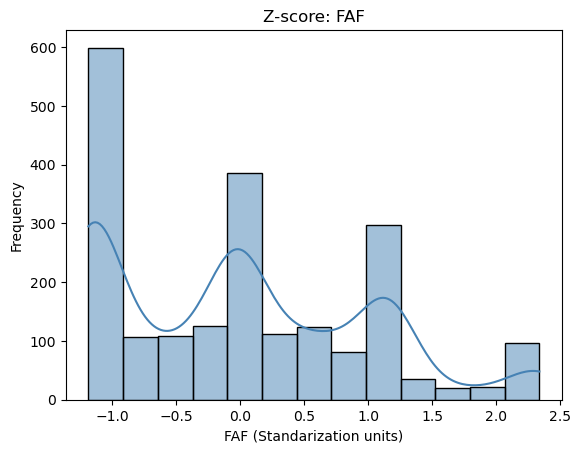

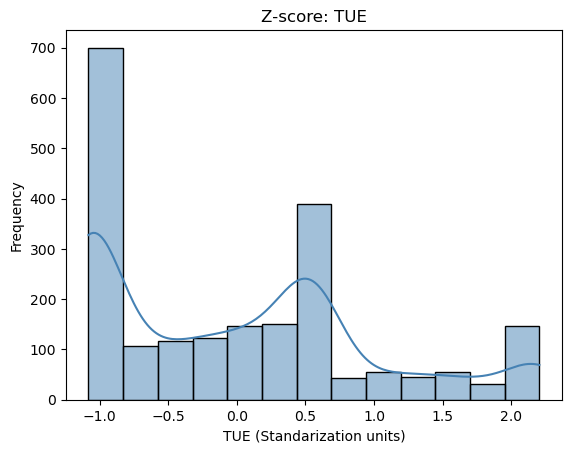

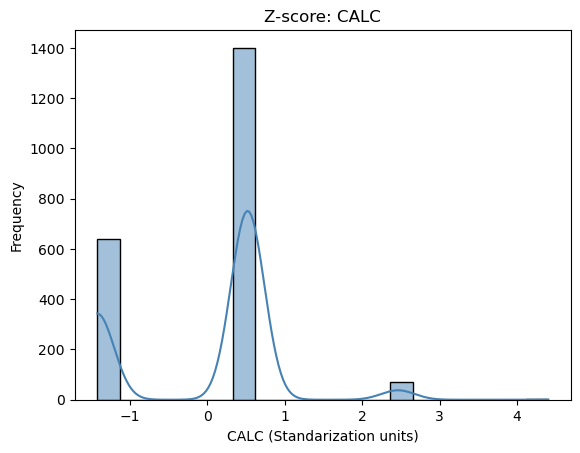

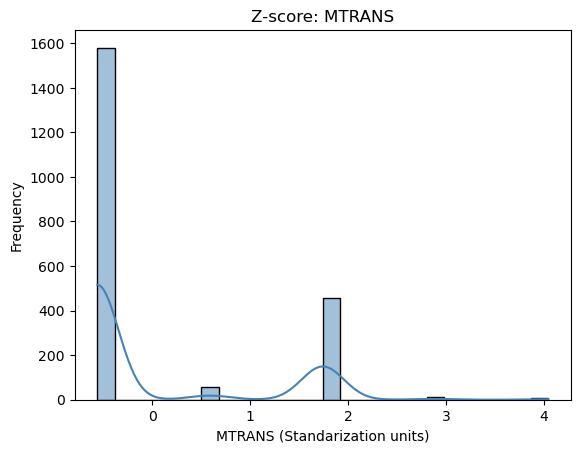

In [22]:
columns_zscore = ['Age', 'Height', 'Weight', 'FCVC', 'CH2O', 'Gender', 'family_history_with_overweight', 'FAVC', 'NCP', 'CAEC', 'SMOKE',
                  'SCC', 'FAF', 'TUE', 'CALC', 'MTRANS']
columns_zscore = [c for c in columns_zscore if c in df.columns]

scaler = StandardScaler()
df_scaled = df.copy()
df[columns_zscore] = scaler.fit_transform(df[columns_zscore].fillna(0))

for col in columns_zscore:
    plt.figure
    sns.histplot(df[col], kde=True, color="steelblue")
    plt.title(f"Z-score: {col}")
    plt.xlabel(f"{col} (Standarization units)")
    plt.ylabel("Frequency")
    plt.show()

# Supervised Learning

In [24]:
# Store the column 'NObeyesdad' in 'label'
label = df[['NObeyesdad']]

# Display first 5 records
label.head()

,NObeyesdad
0,1
1,1
2,1
3,5
4,6


In [25]:
# Drop the label column (Last)
df_1 = df.drop(['NObeyesdad'], axis = 1)

# axis = 1 means along column wise

In [26]:
# Display last 5 records
df_1.head()

,Gender,Age,Height,Weight,family_history_with_overweight,FAVC,FCVC,NCP,CAEC,SMOKE,CH2O,SCC,FAF,TUE,CALC,MTRANS
0,-1.011914,-0.522124,-0.875589,-0.862558,0.472291,-2.759769,-0.785019,0.404153,-0.300346,-0.145900,-0.013073,-0.218272,-1.188039,0.561997,-1.419172,-0.562491
1,-1.011914,-0.522124,-1.947599,-1.168077,0.472291,-2.759769,1.088342,0.404153,-0.300346,6.853997,1.618759,4.581439,2.339750,-1.080625,0.521160,-0.562491
2,0.988227,-0.206889,1.054029,-0.366090,0.472291,-2.759769,-0.785019,0.404153,-0.300346,-0.145900,-0.013073,-0.218272,1.163820,0.561997,2.461491,-0.562491
3,0.988227,0.423582,1.054029,0.015808,-2.117337,-2.759769,1.088342,0.404153,-0.300346,-0.145900,-0.013073,-0.218272,1.163820,-1.080625,2.461491,0.589225
4,0.988227,-0.364507,0.839627,0.122740,-2.117337,-2.759769,-0.785019,-2.167023,-0.300346,-0.145900,-0.013073,-0.218272,-1.188039,-1.080625,0.521160,-0.562491


In [27]:
# Store the values as X and y before applying the ML model
# For a machine learning model, we need to split the data into independent and dependent variables

X = df_1           # Features (independent variables) from the ObesityDataSet

y = label            # Target variable (NObeyesdad) for the prediction

# Regarding the dataset

In [28]:
# Display the label variables of binary types
y.value_counts()

NObeyesdad
2             351
4             324
3             297
5             290
6             290
1             287
0             272
Name: count, dtype: int64

### Train and Test 5%,15%,25%

In [295]:
# Split dataset into training set and test set at 5%
X_train_5, X_test_5, y_train_5, y_test_5 = train_test_split(X, y, test_size = 0.05, random_state = 42) # 5% training and 95% test
# Controls the shuffling applied to the data before applying the split.

# Split dataset into training set and test set at 15%
X_train_15, X_test_15, y_train_15, y_test_15 = train_test_split(X, y, test_size = 0.15, random_state = 42) # 15% training and 85% test

# Split dataset into training set and test set at 25%
X_train_25, X_test_25, y_train_25, y_test_25 = train_test_split(X, y, test_size = 0.25, random_state = 42) # 25% training and 75% test

# Display rows and columns
# Display the rows and columns (dimenions) of an unsplitted dataset
print('Total number of rows and columns for the complete dataset: ', X.shape, y.shape)
print("5% Train", X_train_5.shape, "Test:", X_test_5.shape)
print("15% Train", X_train_15.shape, "Test:", X_test_15.shape)
print("25% Train", X_train_25.shape, "Test:", X_test_25.shape)

Total number of rows and columns for the complete dataset:  (2111, 15) (2111,)
5% Train (2005, 15) Test: (106, 15)
15% Train (1794, 15) Test: (317, 15)
25% Train (1583, 15) Test: (528, 15)


### StandardScaler 5%,15%,25%

In [299]:
# Split 5%
# Create an initialise an object sc by calling a method StandardScaler()
scaled_5 = StandardScaler()
# Train the model by calling the fit_transform method
X_train_5_scaled = scaler.fit_transform(X_train_5)
# Store the transformed data into X_test
X_test_5_scaled = scaler.transform(X_test_5)

# Split 15%
scaled_15 = StandardScaler()
X_train_15_scaled = scaler.fit_transform(X_train_15)
X_test_15_scaled = scaler.transform(X_test_15)

# Split 25%
scaled_25 = StandardScaler()
X_train_25_scaled = scaler.fit_transform(X_train_25)
X_test_25_scaled = scaler.transform(X_test_25)

# SVC

## SVC with 25%

In [348]:
# Create SVC with 25%
cls_svc = SVC(kernel='rbf', C=1.0, random_state=42)

# Training with X_train_scaled
cls_svc.fit(X_train_25_scaled, y_train_25)

# Predictive with X_test_scaled
y_predict = cls_svc.predict(X_test_25_scaled)

In [350]:
# Create a classifier
cls_svc = SVC(kernel = "linear")    # Press shift + tab key simultaneoulsy to get the help for the function or method SVC

# Train the model
cls_svc.fit(X_train_25_scaled, y_train_25)

# Predict the response
y_pred_25_svc = cls_svc.predict(X_test_25_scaled)

In [352]:
# accuracy
print("accuracy:", metrics.accuracy_score(y_test_25, y_pred_25_svc))

# precision, recall and f1 with average = wiegth 
precision = metrics.precision_score(y_test_25, y_pred_25_svc, average="weighted")
recall = metrics.recall_score(y_test_25, y_pred_25_svc, average="weighted")
f1 = metrics.f1_score(y_test_25, y_pred_25_svc, average="weighted")

# Classification report
print("precision:", precision)
print("recall:", recall)
print("f1:", f1)
print(metrics.classification_report(y_test_25, y_pred_25_svc))

accuracy: 0.9526515151515151
precision: 0.954818283495809
recall: 0.9526515151515151
f1: 0.9522730440078984
              precision    recall  f1-score   support

           0       0.89      1.00      0.94        68
           1       0.97      0.83      0.90        78
           2       0.99      0.96      0.97        94
           3       0.95      1.00      0.97        75
           4       1.00      0.99      0.99        79
           5       0.89      0.96      0.93        71
           6       0.97      0.94      0.95        63

    accuracy                           0.95       528
   macro avg       0.95      0.95      0.95       528
weighted avg       0.95      0.95      0.95       528



In [354]:
# Display the unique classes present in y_test and their counts
unique_classes, class_counts = np.unique(y_test_25, return_counts=True)

for cls, count in zip(unique_classes, class_counts):
    print(f"Class {cls}: Count = {count}")

Class 0: Count = 68
Class 1: Count = 78
Class 2: Count = 94
Class 3: Count = 75
Class 4: Count = 79
Class 5: Count = 71
Class 6: Count = 63


In [356]:
# Display the unique classes present in y_test and their counts
unique_classes, class_counts = np.unique(y_pred_25_svc, return_counts=True)

for cls, count in zip(unique_classes, class_counts):
    print(f"Class {cls}: Count = {count}")

Class 0: Count = 76
Class 1: Count = 67
Class 2: Count = 91
Class 3: Count = 79
Class 4: Count = 78
Class 5: Count = 76
Class 6: Count = 61


<Axes: >

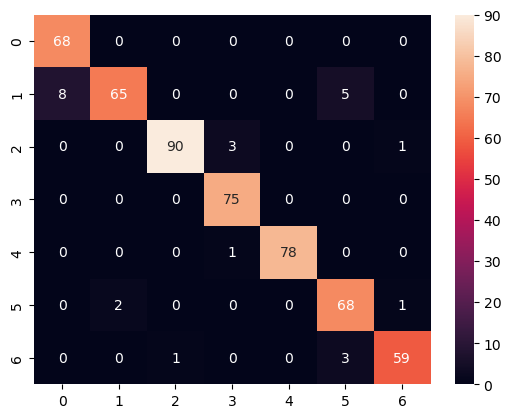

In [358]:
# Call a method predict by using an object classifier 'cls_svm'
y_predict_25 = cls_svc.predict(X_test_25_scaled)

# Calculate cm by calling a method named as 'confusion_matrix'
cm = confusion_matrix(y_test_25, y_predict_25)

# Call a method heatmap() to plot confusion matrix
sns.heatmap(cm, annot = True)

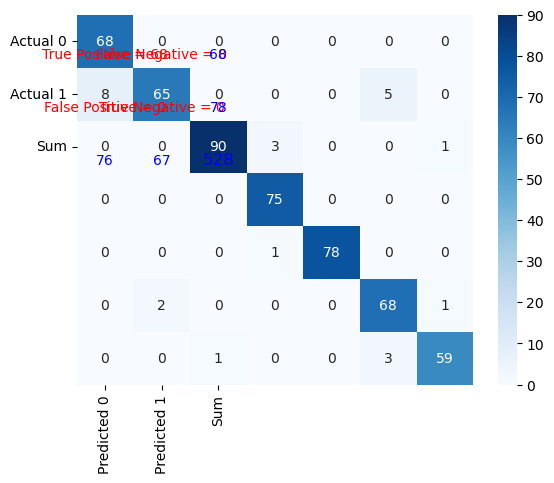

In [360]:
# Call a method predict by using an object classifier 'cls_svm'
y_25_predict = cls_svc.predict(X_test_25_scaled)

# Calculate cm by calling a method named as 'confusion_matrix'
cm = confusion_matrix(y_test_25, y_predict_25)

# Define labels for the confusion matrix
labels = ['True Positive', 'False Negative', 'False Positive', 'True Negative']

# Create a heatmap with annotations and sum of rows/columns
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Predicted 0', 'Predicted 1', 'Sum'], yticklabels=['Actual 0', 'Actual 1', 'Sum'])
# Add labels for TP, FP, TN, FN
for i in range(len(labels)):
    plt.text(i % 2 + 0.5, int(i / 2) + 0.75, str(labels[i]) + " = " + str(cm.flatten()[i]), color='red', fontsize=10, ha='center', va='center')

# Add sum of rows and columns
for i in range(2):
    plt.text(2.5, i + 0.75, str(cm.sum(axis=1)[i]), color='blue', fontsize=10, ha='center', va='center')
    plt.text(i + 0.5, 2.75, str(cm.sum(axis=0)[i]), color='blue', fontsize=10, ha='center', va='center')

# Add overall sum
plt.text(2.5, 2.75, str(cm.sum()), color='blue', fontsize=12, ha='center', va='center')

# Show the plot
plt.show()

In [362]:
print("Columnas en X_train:", X_train_25_scaled.shape[1])
print("Columnas en X_test:", X_test_25_scaled.shape[1])

Columnas en X_train: 15
Columnas en X_test: 15


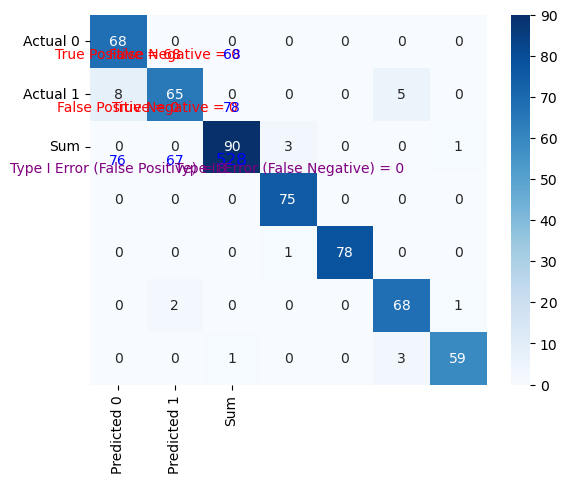

In [364]:
# Call a method predict by using an object classifier 'cls_svm'
y_predict_25 = cls_svc.predict(X_test_25_scaled)

# Calculate cm by calling a method named as 'confusion_matrix'
cm = confusion_matrix(y_test_25, y_predict_25)

# Define labels for the confusion matrix
labels = ['True Positive', 'False Negative', 'False Positive', 'True Negative']

# Create a heatmap with annotations and sum of rows/columns
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Predicted 0', 'Predicted 1', 'Sum'], yticklabels=['Actual 0', 'Actual 1', 'Sum'])

# Add labels for TP, FP, TN, FN
for i in range(len(labels)):
    plt.text(i % 2 + 0.5, int(i / 2) + 0.75, str(labels[i]) + " = " + str(cm.flatten()[i]), color='red', fontsize=10, ha='center', va='center')

# Add sum of rows and columns
for i in range(2):
    plt.text(2.5, i + 0.75, str(cm.sum(axis=1)[i]), color='blue', fontsize=10, ha='center', va='center')
    plt.text(i + 0.5, 2.75, str(cm.sum(axis=0)[i]), color='blue', fontsize=10, ha='center', va='center')

# Add overall sum
plt.text(2.5, 2.75, str(cm.sum()), color='blue', fontsize=12, ha='center', va='center')

# Add Type I and Type II labels
plt.text(0.5, 2.9, f"Type I Error (False Positive) = {cm[1, 0]}", color='purple', fontsize=10, ha='center', va='center')
plt.text(1.5, 2.9, f"Type II Error (False Negative) = {cm[0, 1]}", color='purple', fontsize=10, ha='left', va='center')

# Show the plot
plt.show()

#### Hyperparameters 5%,15%,25%

Hyperparameter in SVC
Results of 5% Train
Best Hyperparameter: {'C': 100, 'gamma': 'scale', 'kernel': 'linear'}
Best Accurancy: 0.9656


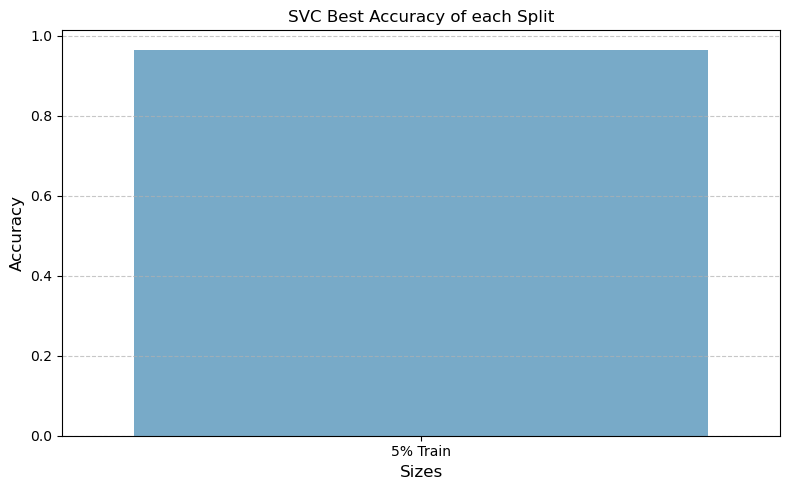

Results of 15% Train
Best Hyperparameter: {'C': 100, 'gamma': 'scale', 'kernel': 'linear'}
Best Accurancy: 0.9638


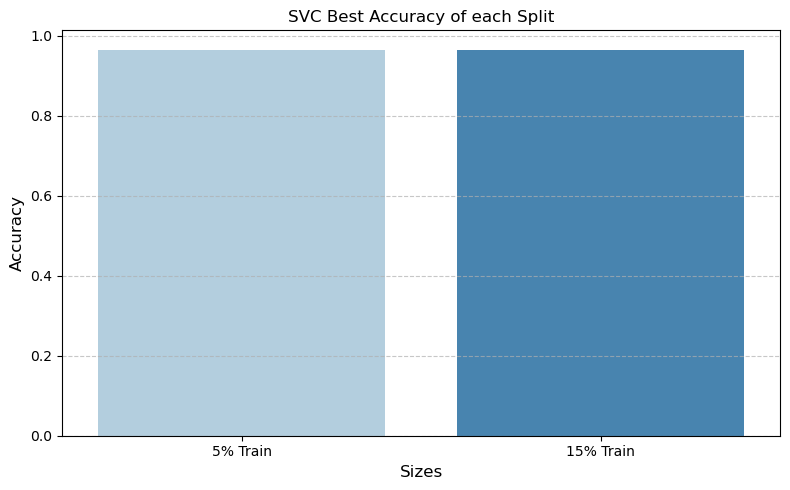

Results of 25% Train
Best Hyperparameter: {'C': 100, 'gamma': 'scale', 'kernel': 'linear'}
Best Accurancy: 0.9589


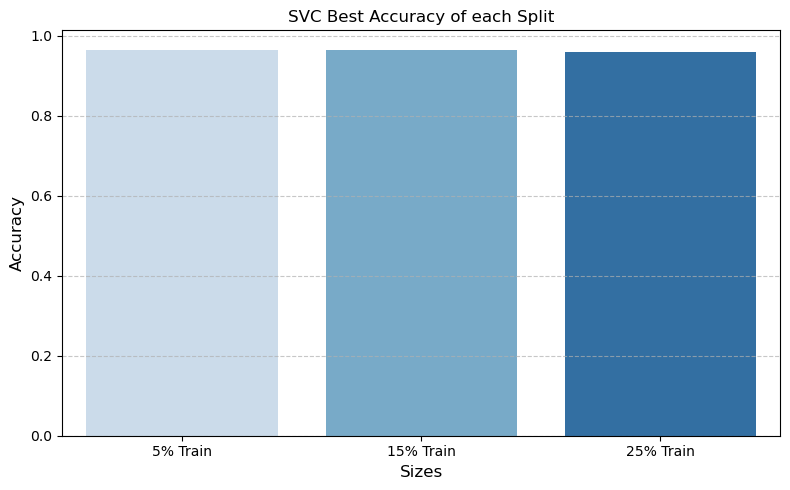

In [517]:
# Definition of the hyperparameter
param_grid_svc = {'C': [0.1, 1, 10, 100], 'kernel': ['linear', 'rbf'], 'gamma': ['scale', 'auto']}

# Split in 5%,15% and 25%
splits = {"5% Train": (X_train_5_scaled, y_train_5), "15% Train": (X_train_15_scaled, y_train_15),"25% Train": (X_train_25_scaled, y_train_25)}

# Best model in svc
best_svc_models = {}
print("Hyperparameter in SVC" )

# Loop of GridSearchCV
results_list = []
for name, (X_train, y_train) in splits.items():
    grid_svc = GridSearchCV(
        estimator=SVC(random_state=42), param_grid=param_grid_svc, cv=5, scoring='accuracy',n_jobs=-1)
    
    # Train the search
    grid_svc.fit(X_train, y_train)
    
    # Safe the best models
    best_svc_models[name] = grid_svc.best_estimator_

    #Accuracy and split safe
    results_list.append({'Split': name,'Best Accuracy': grid_svc.best_score_})
    
    df_results = pd.DataFrame(results_list)
    
    #Graph
    plt.figure(figsize=(8, 5))
    ax = sns.barplot(data=df_results, x='Split', y='Best Accuracy', palette='Blues')
    # Print
    print(f"Results of {name}")
    print(f"Best Hyperparameter: {grid_svc.best_params_}")
    print(f"Best Accurancy: {grid_svc.best_score_:.4f}")
    plt.title('SVC Best Accuracy of each Split')
    plt.xlabel('Sizes', fontsize=12)
    plt.ylabel('Accuracy', fontsize=12)
    plt.grid(axis='y', linestyle='--', alpha=0.7)
    plt.tight_layout()
    plt.show()

### CrossValidation SVC 5%,15%,25%

In [478]:
# CrossValidation 5%,15%,25%
cls_svc = SVC(kernel='linear', random_state=42)
cv_5 = cross_val_score(cls_svc, X_train_5_scaled, y_train_5, cv=5, scoring='accuracy')
cv_15 = cross_val_score(cls_svc, X_train_15_scaled, y_train_15, cv=5, scoring='accuracy')
cv_25 = cross_val_score(cls_svc, X_train_25_scaled, y_train_25, cv=5, scoring='accuracy')

# Print accurrancy of crossvalidation
print(f"SVC Crossvalidation Accuracy 5%:  {cv_5.mean():.4f} | {cv_5.std():.4f}")
print(f"SVC Crossvalidation Accuracy 15%: {cv_15.mean():.4f} | {cv_15.std():.4f}")
print(f"SVC Crossvalidation Accuracy 25%: {cv_25.mean():.4f} | {cv_25.std():.4f}")

SVC Crossvalidation Accuracy 5%:  0.9521 | 0.0079
SVC Crossvalidation Accuracy 15%: 0.9459 | 0.0102
SVC Crossvalidation Accuracy 25%: 0.9419 | 0.0088


# KNN Model

## KNN with 25%

In [483]:
# Create KNN Classifier 25%
col_kNN = KNeighborsClassifier(n_neighbors = 3)

# Train the model using the training sets
col_kNN.fit(X_train_25_scaled, y_train_25)

# Predict the response for test dataset
y_pred_knn_25 = col_kNN.predict(X_test_25_scaled)

In [485]:
# Model Accuracy, how often is the classifier correct?
print( "Accuracy: {:.2f}".format(metrics.accuracy_score(y_test_25, y_pred_knn_25)) )

Accuracy: 0.81


## Matrix Confusion

<Axes: >

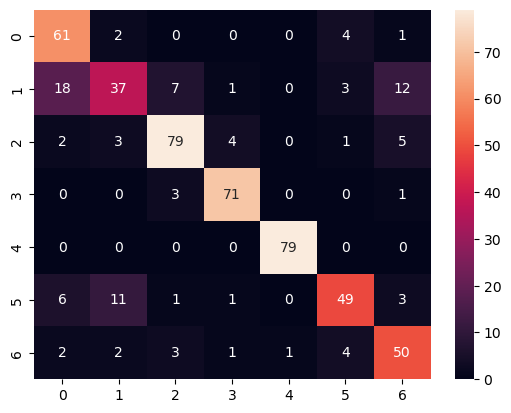

In [488]:
# Call a method predict by using an object classifier 'cls_svm'
y_predict_25 = col_kNN.predict(X_test_25_scaled)

# Calculate cm by calling a method named as 'confusion_matrix'
cm = confusion_matrix(y_test_25, y_predict_25)

# Call a method heatmap() to plot confusion matrix
sns.heatmap(cm, annot = True)

## Classification Report

In [491]:
# Display the classification report
print(classification_report(y_test_25, y_predict_25))

              precision    recall  f1-score   support

           0       0.69      0.90      0.78        68
           1       0.67      0.47      0.56        78
           2       0.85      0.84      0.84        94
           3       0.91      0.95      0.93        75
           4       0.99      1.00      0.99        79
           5       0.80      0.69      0.74        71
           6       0.69      0.79      0.74        63

    accuracy                           0.81       528
   macro avg       0.80      0.81      0.80       528
weighted avg       0.81      0.81      0.80       528



#### Hyperparameters 5%,15%,25%

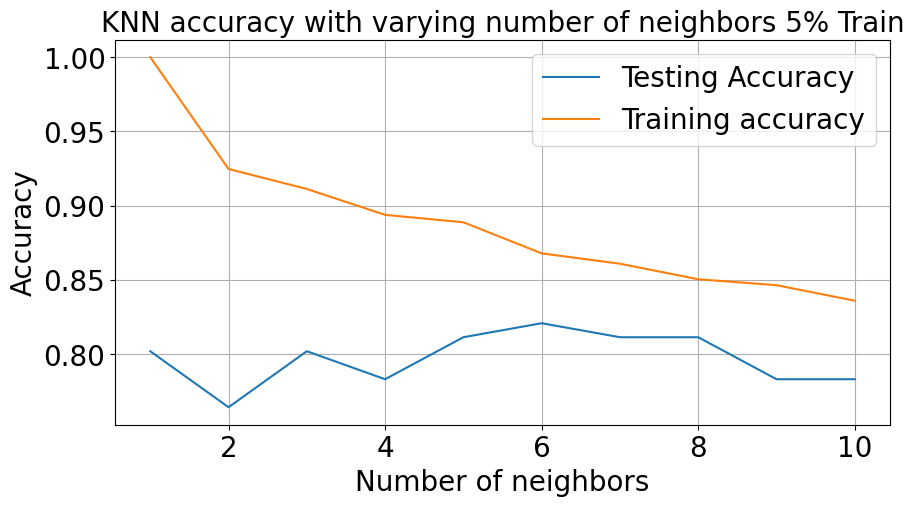

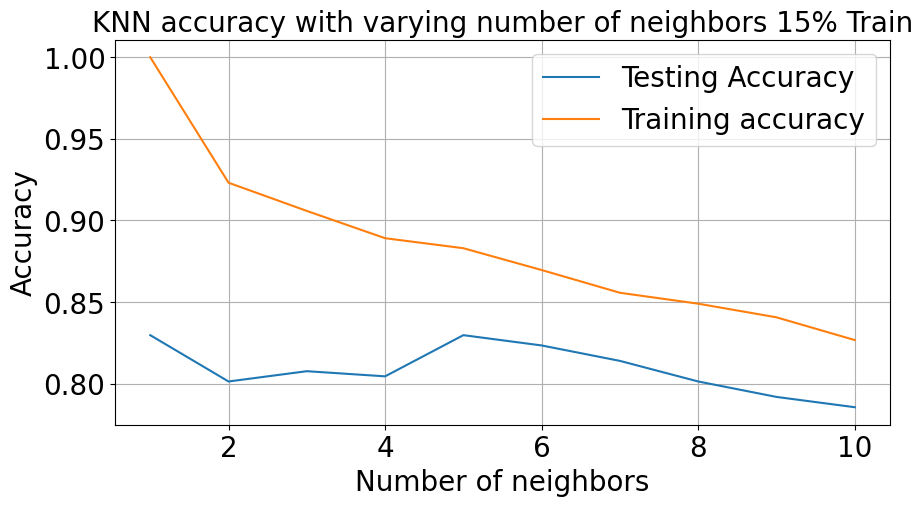

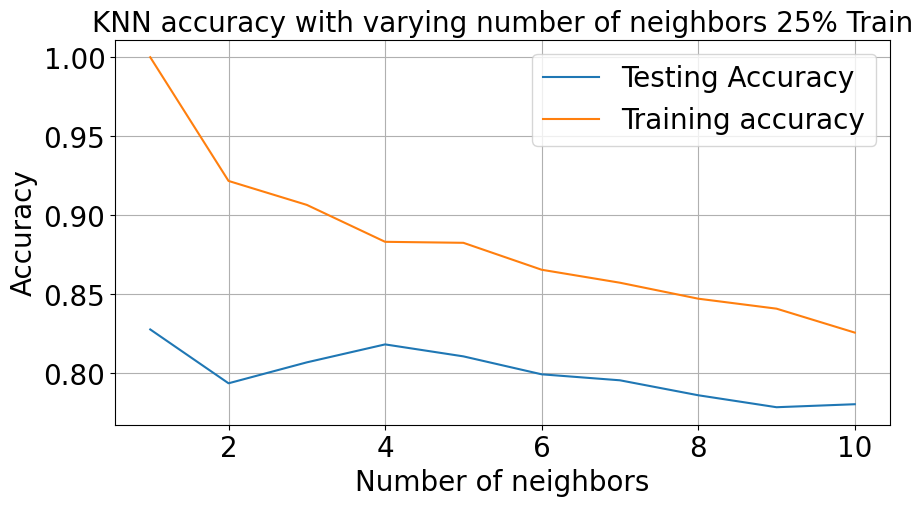

In [465]:
neighbors = np.arange(1, 11)   # number of neighbors

# Split in 5%,15% and 25%
splits = {"5% Train": (X_train_5_scaled, y_train_5, X_test_5_scaled, y_test_5), "15% Train": (X_train_15_scaled, y_train_15, X_test_15_scaled, y_test_15),
          "25% Train": (X_train_25_scaled, y_train_25, X_test_25_scaled, y_test_25)}

# Graph every split in loop
for name, (X_train, y_train, X_test, y_test) in splits.items():
    train_accuracy = np.zeros(len(neighbors))  #Declare and initialise the matrix
    test_accuracy = np.zeros(len(neighbors))   #Declare and initialise the matrix
    
# Call fit method to implement the ML KNeighborsClassifier model
    for i, k in enumerate(neighbors):
        col_kNN = KNeighborsClassifier(n_neighbors=k)
        col_kNN.fit(X_train, y_train)
        train_accuracy[i] = col_kNN.score(X_train, y_train)  # Save the score value in the train_accuracy array 
        test_accuracy[i] = col_kNN.score(X_test, y_test)  # Save the score value in the train_accuracy array 

# Print
    plt.figure(figsize = (10, 5))
    plt.title(f'KNN accuracy with varying number of neighbors {name}', fontsize = 20)
    plt.plot(neighbors, test_accuracy, label = 'Testing Accuracy')
    plt.plot(neighbors, train_accuracy, label = 'Training accuracy')
    plt.legend(prop={'size': 20})
    plt.xlabel('Number of neighbors', fontsize = 20)
    plt.ylabel('Accuracy', fontsize = 20)
    plt.xticks(fontsize = 20)
    plt.yticks(fontsize = 20)
    plt.grid(True)
    plt.show()

### CrossValidation 5%,15%,25%

In [439]:
# CrossValidation 5%,15%,25%
col_kNN = KNeighborsClassifier(n_neighbors=3)
cv_knn_5 = cross_val_score(col_kNN, X_train_5_scaled, y_train_5, cv=5, scoring='accuracy')
cv_knn_15 = cross_val_score(col_kNN, X_train_15_scaled, y_train_15, cv=5, scoring='accuracy')
cv_knn_25 = cross_val_score(col_kNN, X_train_25_scaled, y_train_25, cv=5, scoring='accuracy')

# Print accurrancy of crossvalidation
print(f"kNN Crossvalidation Accuracy 5%:  {cv_knn_5.mean():.4f} | {cv_knn_5.std():.4f}")
print(f"kNN Crossvalidation Accuracy 15%: {cv_knn_15.mean():.4f} | {cv_knn_15.std():.4f}")
print(f"kNN Crossvalidation Accuracy 25%: {cv_knn_25.mean():.4f} | {cv_knn_25.std():.4f}")

kNN Crossvalidation Accuracy 5%:  0.8304 | 0.0138
kNN Crossvalidation Accuracy 15%: 0.8200 | 0.0086
kNN Crossvalidation Accuracy 25%: 0.8200 | 0.0179


## Random Forest

### Random Forest with 25%

In [443]:
X = df_1.iloc[:, :-1]   # select all columns except the last one (features)
y = label.iloc[:, -1]    # select the last column as labels (Class)

In [447]:
#Create a Gaussian Classifier
clf_RF = RandomForestClassifier(n_estimators = 1000)

#Train the model using the training sets y_pred=clf.predict(X_test)
clf_RF.fit(X_train_25, y_train_25)

y_pred_25_rf = clf_RF.predict(X_test_25)

In [449]:
# Model Accuracy, how often is the classifier correct?
print("Accuracy:",metrics.accuracy_score(y_test_25, y_pred_25_rf))

# Rounded upto 2 decimal places
print( "Accuracy: {:.2f}".format(metrics.accuracy_score(y_test_25, y_pred_25_rf)) )

Accuracy: 0.9356060606060606
Accuracy: 0.94


In [451]:
# Predict new obeyesdad
prediction = clf_RF.predict([[13.2, 2.1, 2.4, 15.6, 100, 2.6, 2.5, 0.3, 1.9, 5.0, 1.0, 3.2, 1000, 0,1]])

print("Predicted NObeyesdad Class:", prediction[0])

Predicted NObeyesdad Class: 3


In [453]:
#Create a Gaussian Classifier
clf_RF = RandomForestClassifier(n_estimators = 1000)

#Train the model using the training sets y_pred=clf.predict(X_test)
clf_RF.fit(X_train_25 ,y_train_25)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",1000
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metri

In [455]:
feature_imp = pd.Series(clf_RF.feature_importances_).sort_values(ascending = False)
feature_imp

3     0.317092
1     0.103610
2     0.100190
6     0.092541
7     0.056391
13    0.053916
0     0.052850
10    0.051372
12    0.049792
8     0.034915
14    0.032275
4     0.030709
5     0.015723
11    0.006077
9     0.002546
dtype: float64

### Matrix Confusion

<Axes: >

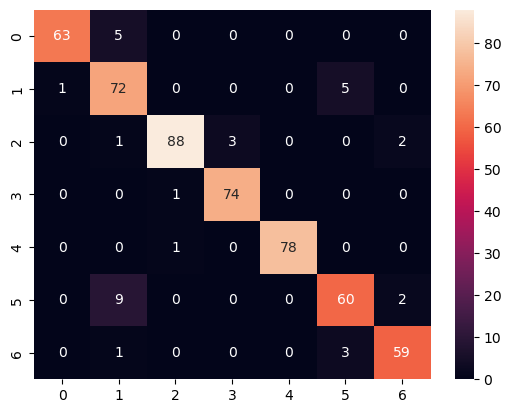

In [494]:
# Matrix de confusion using RF
cm_rf = confusion_matrix(y_test_25, y_pred_25_rf)

# Call a method heatmap() to plot confusion matrix
sns.heatmap(cm_rf, annot = True)

### Hyperparameter 5%,15%,25%

Random Forest Hyperparameter
Results of 5% Train:
Best Hyperparameters: {'criterion': 'entropy', 'max_depth': None, 'n_estimators': 200}
Best Accuracy: 0.9546
Results of 15% Train:
Best Hyperparameters: {'criterion': 'entropy', 'max_depth': None, 'n_estimators': 200}
Best Accuracy: 0.9554
Results of 25% Train:
Best Hyperparameters: {'criterion': 'entropy', 'max_depth': None, 'n_estimators': 200}
Best Accuracy: 0.9558


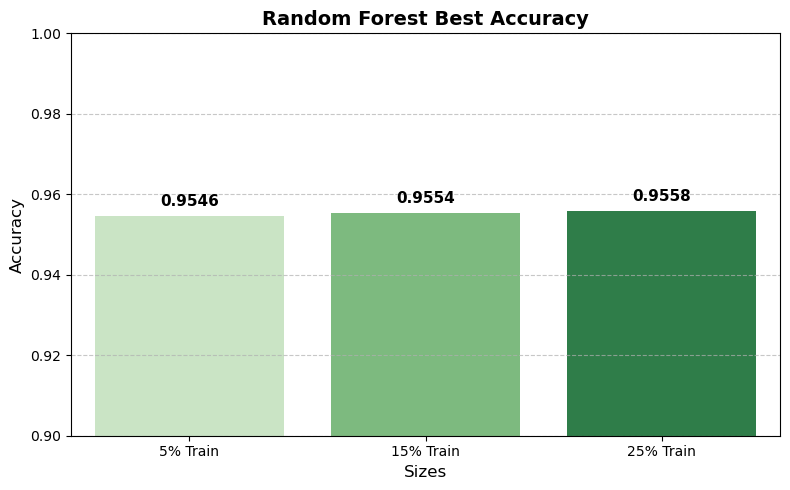

In [525]:
# Definition of the hyperparameter
param_grid_rf = {'n_estimators': [50, 100, 200],'max_depth': [None, 10, 20], 'criterion': ['gini', 'entropy'],}

# Split in 5%,15% and 25%
splits = {'5% Train': (X_train_5_scaled, y_train_5), '15% Train': (X_train_15_scaled, y_train_15), '25% Train': (X_train_25_scaled, y_train_25)}

# Graph
best_rf_models = {}
rf_results_list = []
print('Random Forest Hyperparameter')

# Loop of GridSearchCV
for name, (X_train, y_train) in splits.items():
  grid_rf = GridSearchCV(estimator=RandomForestClassifier(random_state=42), param_grid=param_grid_rf, cv=5, scoring='accuracy', n_jobs=-1,)

  # Train the search
  grid_rf.fit(X_train, y_train)

  # Save the best models
  best_rf_models[name] = grid_rf.best_estimator_

  # Save the best result
  rf_results_list.append({'Split': name, 'Best Accuracy': grid_rf.best_score_})

   # Print
  print(f'Results of {name}:')
  print(f'Best Hyperparameters: {grid_rf.best_params_}')
  print(f'Best Accuracy: {grid_rf.best_score_:.4f}')

# Convert the data
df_rf_results = pd.DataFrame(rf_results_list)

# Graph
plt.figure(figsize=(8, 5))
ax = sns.barplot(data=df_rf_results, x='Split', y='Best Accuracy', palette='Greens')

# Print
for p in ax.patches:
  ax.annotate(f'{p.get_height():.4f}', (p.get_x() + p.get_width() / 2.0, p.get_height()), ha='center', va='bottom', fontsize=11, fontweight='bold', xytext=(0, 5), textcoords='offset points')
plt.ylim(0.90, 1.0)
plt.title('Random Forest Best Accuracy', fontsize=14, fontweight='bold')
plt.xlabel('Sizes', fontsize=12)
plt.ylabel('Accuracy', fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

### CrossValidation 5%,15%,25%

In [500]:
# CrossValidation 5%,15%,25%
cls_rf = RandomForestClassifier(random_state=42)
cv_rf_5 = cross_val_score(cls_rf, X_train_5_scaled, y_train_5, cv=5, scoring='accuracy')
cv_rf_15 = cross_val_score(cls_rf, X_train_15_scaled, y_train_15, cv=5, scoring='accuracy')
cv_rf_25 = cross_val_score(cls_rf, X_train_25_scaled, y_train_25, cv=5, scoring='accuracy')

# Print accurrancy of crossvalidation
print(f"Random Forest Crossvalidation Accuracy 5%:  {cv_rf_5.mean():.4f} | {cv_rf_5.std():.4f}")
print(f"Random Forest Crossvalidation Accuracy 15%: {cv_rf_15.mean():.4f} | {cv_rf_15.std():.4f}")
print(f"Random Forest Crossvalidation Accuracy 25%: {cv_rf_25.mean():.4f} | {cv_rf_25.std():.4f}")

Random Forest Crossvalidation Accuracy 5%:  0.9481 | 0.0095
Random Forest Crossvalidation Accuracy 15%: 0.9443 | 0.0093
Random Forest Crossvalidation Accuracy 25%: 0.9495 | 0.0087


# Comparation of KNN, SVC and Ramdon Forest

In [504]:
# Split in 5%,15% and 25%
splits = {"5% Train": (X_train_5_scaled, y_train_5, X_test_5_scaled, X_test_5, y_test_5), "15% Train": (X_train_15_scaled, y_train_15, X_test_15_scaled, X_test_15, y_test_15),
          "25% Train": (X_train_25_scaled, y_train_25, X_test_25_scaled, X_test_25, y_test_25)}
comparison_data = []

# Iterate through each split
for name, (X_train_scaled, y_train, X_test_scaled, X_test_raw, y_test) in splits.items():
    
    # Calculate KNN best 
    best_knn_accur = 0
    for k in range(1, 11):
        knn = KNeighborsClassifier(n_neighbors=k)
        knn.fit(X_train_scaled, y_train)
        accur = knn.score(X_test_scaled, y_test)
        if accur > best_knn_accur:
            best_knn_accur = accur
            
    # Get SVC prediction using best_svc
    if 'best_svc_models' in locals() and name in best_svc_models:
        predict_svc = best_svc_models[name].predict(X_test_scaled)
        svc_accur = accuracy_score(y_test, predict_svc)
    else:
        predict_svc = cls_svc.predict(X_test_scaled)
        svc_accur = accuracy_score(y_test, predict_svc)
        
    # Get Random Forest prediction using best_rf
    if 'best_rf_models' in locals() and name in best_rf_models:
        predict_rf = best_rf_models[name].predict(X_test_raw)
        rf_accur = accuracy_score(y_test, predict_rf)
    else:
        predict_rf = clf_RF.predict(X_test_raw)
        rf_accur = accuracy_score(y_test, predict_rf)

    # Comparison results
    comparison_data.append({'Split': name, 'SVC Accuracy': svc_accur, 'KNN Accuracy': best_knn_accur,'Random Forest Accuracy': rf_accur})

# Print
results_df = pd.DataFrame(comparison_data)
print("Model Comparison")
print(results_df.to_string(index=False))

Model Comparison
    Split  SVC Accuracy  KNN Accuracy  Random Forest Accuracy
 5% Train      0.962264      0.820755                0.962264
15% Train      0.974763      0.829653                0.949527
25% Train      0.977273      0.827652                0.931818


# F1Score comparation

In [511]:
# Split in 5%,15% and 25%
test_splits = {"5% Train": (X_test_5_scaled, X_test_5, y_test_5), "15% Train": (X_test_15_scaled, X_test_15, y_test_15),"25% Train": (X_test_25_scaled, X_test_25, y_test_25)}
comparison_data = []

# Loop over splits F1-Score for all 3 models
for name, (X_test_scaled, X_test_raw, y_test) in test_splits.items():

    # SVC F1-Score
    if 'best_svc_models' in locals() and name in best_svc_models:
        predict_svc = best_svc_models[name].predict(X_test_scaled)
    else:
        predict_svc = cls_svc.predict(X_test_scaled)
    
    # KNN F1-Score 
    if 'best_knn_models' in locals() and name in best_knn_models:
        predict_knn = best_knn_models[name].predict(X_test_scaled)
    else:
        best_knn_accur, predict_knn = 0, None
        for k in range(1, 11):
            knn = KNeighborsClassifier(n_neighbors=k)
            knn.fit(splits[name][0], splits[name][1])
            if knn.score(X_test_scaled, y_test) > best_knn_accur:
                best_knn_accur = knn.score(X_test_scaled, y_test)
                predict_knn = knn.predict(X_test_scaled)
                
    # Random Forest F1-Score
    if 'best_rf_models' in locals() and name in best_rf_models:
        predict_rf = best_rf_models[name].predict(X_test_raw)
    else:
        predict_rf = clf_RF.predict(X_test_raw)

    # F1-Score metrics
    comparison_data.append({'Split': name, 'SVC Accuracy': accuracy_score(y_test, predict_svc), 'KNN Accuracy': accuracy_score(y_test, predict_knn),
                            'Random Forest Accuracy': accuracy_score(y_test, predict_rf), 'KNN F1-Macro': f1_score(y_test, predict_knn, average='macro'),
                            'SVC F1-Macro': f1_score(y_test, predict_svc, average='macro'),'Random Forest F1-Macro': f1_score(y_test, predict_rf, average='macro')})

# Print
results_df = pd.DataFrame(comparison_data)
print("Macro F1-Score Comparison")
print(results_df.to_string(index=False))

Macro F1-Score Comparison
    Split  SVC Accuracy  KNN Accuracy  Random Forest Accuracy  KNN F1-Macro  SVC F1-Macro  Random Forest F1-Macro
 5% Train      0.962264      0.820755                0.962264      0.810223      0.955958                0.952721
15% Train      0.974763      0.829653                0.949527      0.819630      0.971704                0.947426
25% Train      0.977273      0.827652                0.931818      0.820943      0.975920                0.930881
